# Predicting online purchases — Online Shoppers Purchasing Intention

**Data.** UCI dataset 468: 12,330 browsing sessions from one Turkish online retailer over one year.
The target `Revenue` records whether the session ended in a purchase.

**Business action.** Flag likely buyers *during* the session so live sales support (chat, assisted
checkout) goes to them. A missed buyer (false negative) is a lost sale; a flagged non-buyer
(false positive) is a wasted support slot. A lost sale is judged five times as costly, so
**C_FN / C_FP = 5**. That assumption is stress-tested in §13.

**How to read this notebook.** Every step states its **Purpose**, **Method**, the **Result**
(the code output), **What it tells us**, and where relevant the **Real-world meaning**.
Steps that did not help are kept on purpose: §11 records every variant tried, including failures.

**Workflow.** Split once → all development by cross-validation on the training data → selection
metric declared before any model (below) → test set used once, for the chosen model → refit on all data.

## §0 Selection metric — declared before any model is fitted

- **Primary:** cross-validated **ROC AUC** on the training data, over 25 folds (5-fold × 5 repeats).
  AUC is the probability that a random buyer is scored above a random non-buyer: it measures
  ranking quality independently of any threshold.
- **Tie-break:** expected cost per session at C_FN/C_FP = 5, each model at its own cost-minimising threshold.
- **Significance:** differences are tested with the Nadeau–Bengio corrected paired t-test. Repeated-CV
  folds share training rows, so an ordinary t-test would overstate confidence.
- **Parsimony:** a more complex variant is carried forward only if its gain is statistically significant.
- The test set plays no part in any choice.

In [1]:
import os, time, warnings
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, FunctionTransformer,
                                   PowerTransformer, QuantileTransformer, PolynomialFeatures)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import (LinearDiscriminantAnalysis as LDA,
                                           QuadraticDiscriminantAnalysis as QDA)
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split, GridSearchCV)
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.inspection import PartialDependenceDisplay
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 4); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
try:
    display
except NameError:                                   # allows running outside Jupyter
    display = lambda x: print(x.to_string() if hasattr(x, "to_string") else x)

SEED, TEST_SIZE, COST = 42, 0.25, 5.0
T_STAR = 1 / (1 + COST)
skf  = StratifiedKFold(5, shuffle=True, random_state=SEED)                     # one 5-fold pass
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)      # 25 folds
T0 = time.time()
print(f"C_FN/C_FP = {COST}  ->  Bayes-optimal threshold t* = {T_STAR:.4f}")

C_FN/C_FP = 5.0  ->  Bayes-optimal threshold t* = 0.1667


## §1 Load and split once

**Purpose.** Seal a test set before anything else, so no decision can be influenced by it.
**Method.** Stratified 75/25 split (seed 42) so both parts keep the same purchase rate. Integer
codes (operating system, browser, region, traffic type) and the weekend flag are cast to text, so
they are treated as categories rather than quantities.

In [2]:
os.makedirs("data", exist_ok=True)
path = "data/uci_468.csv"
if not os.path.exists(path):
    r = requests.get("https://archive.ics.uci.edu/static/public/468/data.csv", timeout=600)
    r.raise_for_status(); open(path, "wb").write(r.content)

df = pd.read_csv(path)
y_all = df.pop("Revenue").astype(bool).astype(int)
for c in ["OperatingSystems", "Browser", "Region", "TrafficType", "Weekend"]:
    df[c] = df[c].astype(str)            # codes and flags are categories, not quantities

Xtr, Xte, ytr, yte = train_test_split(df, y_all, test_size=TEST_SIZE,
                                      stratify=y_all, random_state=SEED)
Xtr, Xte = Xtr.reset_index(drop=True), Xte.reset_index(drop=True)
ytr, yte = ytr.reset_index(drop=True), yte.reset_index(drop=True)
del df, y_all                            # the pooled frame cannot be used by accident
print(f"train {len(Xtr):,} sessions, {int(ytr.sum()):,} purchases ({ytr.mean():.4f})")
print(f"test  {len(Xte):,} sessions, {int(yte.sum()):,} purchases ({yte.mean():.4f})  [SEALED until §14]")

train 9,247 sessions, 1,431 purchases (0.1548)
test  3,083 sessions, 477 purchases (0.1547)  [SEALED until §14]


**What it tells us.** 9,247 training sessions (1,431 purchases) and 3,083 test sessions (477 purchases): a 15.5% purchase rate in both. The pooled frame is deleted, so the test set cannot leak back in.

## §2 Exploratory analysis — training data only

### 2.1 The variables
**Purpose.** Establish what we are modelling and whether anything is missing.

In [3]:
NUM = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
       "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues"]
CAT = ["SpecialDay", "Month", "OperatingSystems", "Browser", "Region", "TrafficType",
       "VisitorType", "Weekend"]
DESC = {
 "Administrative": "account-management pages visited", "Administrative_Duration": "seconds on those pages",
 "Informational": "information pages visited (about, contact)", "Informational_Duration": "seconds on those pages",
 "ProductRelated": "product pages visited", "ProductRelated_Duration": "seconds on product pages",
 "BounceRates": "avg bounce rate of pages visited (Google Analytics)",
 "ExitRates": "avg exit rate of pages visited (Google Analytics)",
 "PageValues": "avg 'page value' of pages visited (Google Analytics)",
 "SpecialDay": "closeness to a holiday such as Valentine's Day (0-1)", "Month": "month of visit",
 "OperatingSystems": "OS code", "Browser": "browser code", "Region": "region code",
 "TrafficType": "traffic source code", "VisitorType": "new / returning / other",
 "Weekend": "visit on a weekend"}
display(pd.DataFrame({"type": ["numeric" if c in NUM else "categorical" for c in NUM + CAT],
                      "distinct values": [Xtr[c].nunique() for c in NUM + CAT],
                      "% missing": [100 * Xtr[c].isna().mean() for c in NUM + CAT],
                      "meaning": [DESC[c] for c in NUM + CAT]}, index=NUM + CAT))
print(f"{len(NUM + CAT)} predictors ({len(NUM)} numeric, {len(CAT)} categorical); "
      f"total missing cells: {int(Xtr.isna().sum().sum())}")

,type,distinct values,% missing,meaning
Administrative,numeric,26,0.0,account-management pages visited
Administrative_Duration,numeric,2677,0.0,seconds on those pages
Informational,numeric,17,0.0,"information pages visited (about, contact)"
Informational_Duration,numeric,1022,0.0,seconds on those pages
ProductRelated,numeric,278,0.0,product pages visited
ProductRelated_Duration,numeric,7336,0.0,seconds on product pages
BounceRates,numeric,1506,0.0,avg bounce rate of pages visited (Google Analy...
ExitRates,numeric,3748,0.0,avg exit rate of pages visited (Google Analytics)
PageValues,numeric,2042,0.0,avg 'page value' of pages visited (Google Anal...
SpecialDay,categorical,6,0.0,closeness to a holiday such as Valentine's Day...


17 predictors (9 numeric, 8 categorical); total missing cells: 0


**What it tells us.** 17 predictors (9 numeric, 8 categorical) and no missing values. After §3 removes one, **16 predictors remain, well above the minimum of five**. With nothing missing, the imputers in the pipeline are a safeguard rather than a correction.

### 2.2 Class balance
**Purpose.** The share of buyers governs how accuracy, sensitivity and the threshold behave.

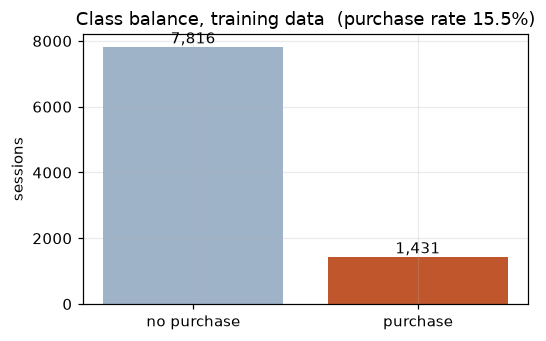

A model that always predicts 'no purchase' is 84.5% accurate and catches 0 buyers.


In [4]:
rate = ytr.mean()
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(["no purchase", "purchase"], [int((1 - ytr).sum()), int(ytr.sum())], color=["#9fb3c8", "#c0562c"])
for i, v in enumerate([int((1 - ytr).sum()), int(ytr.sum())]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_ylabel("sessions"); ax.set_title(f"Class balance, training data  (purchase rate {rate:.1%})")
plt.tight_layout(); plt.show()
print(f"A model that always predicts 'no purchase' is {1 - rate:.1%} accurate and catches 0 buyers.")

**What it tells us.** Only 15.5% of sessions buy, so accuracy is misleading: predicting "no purchase" for everyone scores 84.5% and catches no buyers. That is why we evaluate with AUC, sensitivity and specificity.
**Real-world meaning.** Most visitors browse without buying. The model's job is to find the minority worth a salesperson's time.

### 2.3 Numeric features by class
**Purpose.** Find which behaviours separate buyers from non-buyers, and what shape the data has.
**Method.** Overlaid histograms; medians by class; the Mann-Whitney U test, which compares two
distributions without assuming normality. Its AUC form is the probability that a random buyer has a
higher value than a random non-buyer (0.5 = no separation; below 0.5 = buyers tend to be lower).

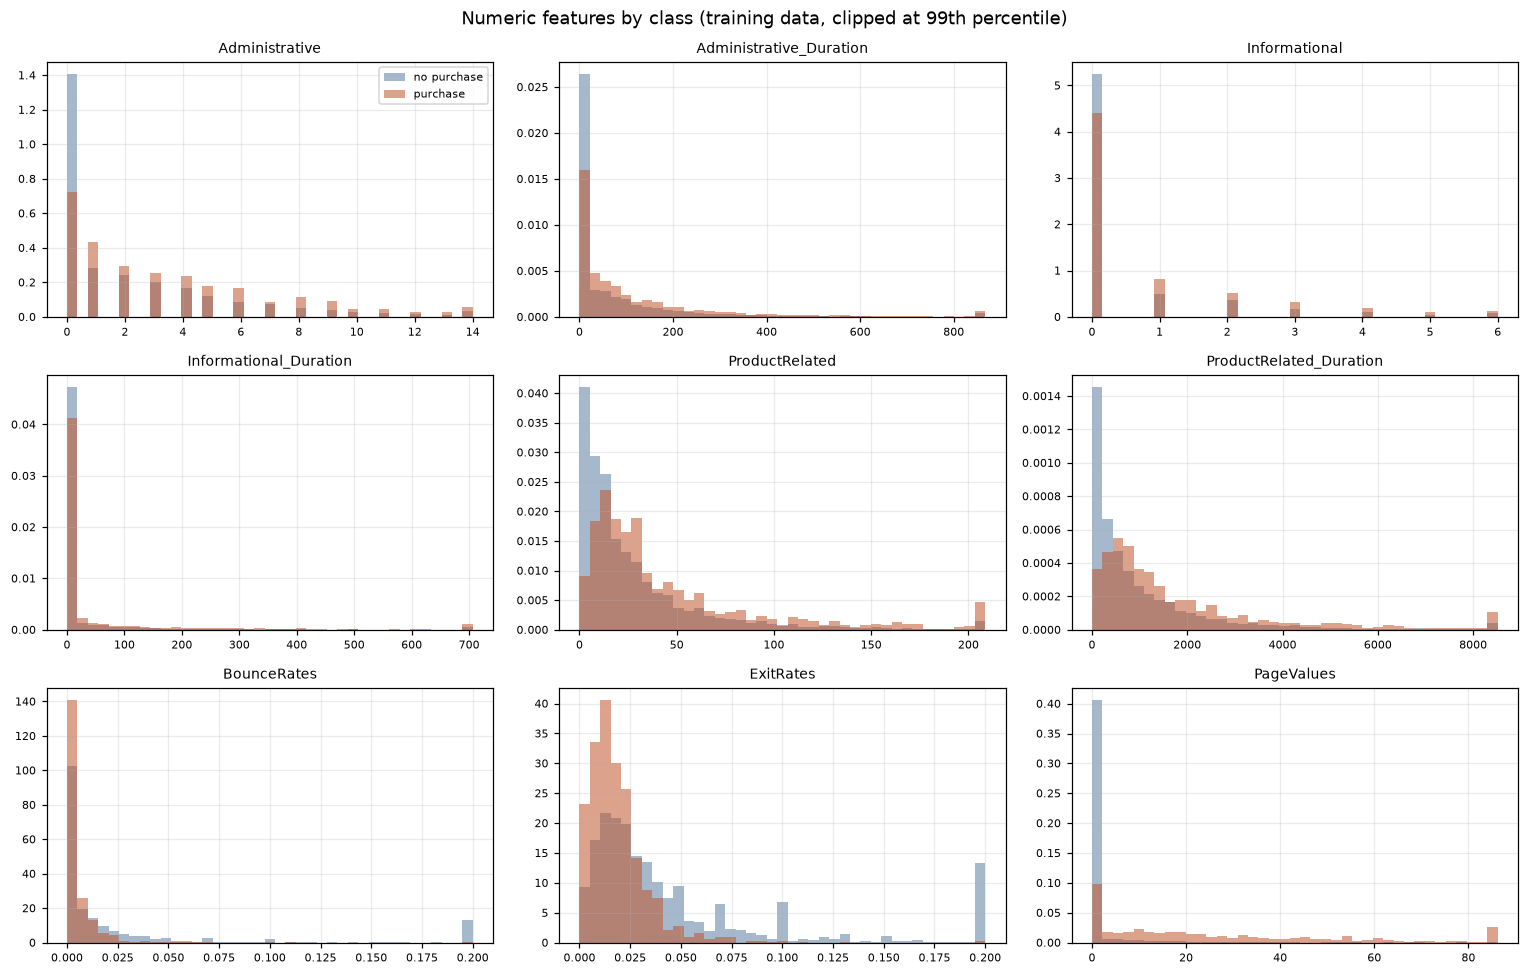

,median (no),median (buy),skew,% zeros,Mann-Whitney p,AUC = P(buyer > non-buyer)
feature,,,,,,
Administrative,0.0000,2.0000,1.9881,46.6746,5.8865e-64,0.6326
Administrative_Duration,0.0000,54.8000,5.7151,47.6479,1.1382e-63,0.6320
Informational,0.0000,0.0000,4.1901,78.6417,2.4307e-28,0.5656
Informational_Duration,0.0000,0.0000,7.8000,80.5450,6.1326e-28,0.5628
ProductRelated,16.0000,29.0000,4.4013,0.2812,2.1425e-87,0.6644
ProductRelated_Duration,506.2917,1123.2467,8.2264,6.1750,1.0907e-101,0.6777
BounceRates,0.0042,0.0000,2.9341,45.0633,3.1152e-51,0.3809
ExitRates,0.0286,0.0155,2.1308,0.6380,4.7418e-147,0.2857
PageValues,0.0000,17.5360,6.2503,77.7441,0.0000e+00,0.8703


In [5]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
rows = []
for ax, c in zip(axes.ravel(), NUM):
    v0, v1 = Xtr.loc[ytr == 0, c], Xtr.loc[ytr == 1, c]
    hi = Xtr[c].quantile(0.99)
    bins = np.linspace(0, hi, 40)
    ax.hist(v0.clip(upper=hi), bins=bins, density=True, alpha=.55, label="no purchase", color="#5b7fa3")
    ax.hist(v1.clip(upper=hi), bins=bins, density=True, alpha=.55, label="purchase", color="#c0562c")
    ax.set_title(c, fontsize=9); ax.tick_params(labelsize=7)
    U, p = stats.mannwhitneyu(v1, v0, alternative="two-sided")
    auc = U / (len(v1) * len(v0))
    rows.append({"feature": c, "median (no)": v0.median(), "median (buy)": v1.median(),
                 "skew": stats.skew(Xtr[c]), "% zeros": 100 * (Xtr[c] == 0).mean(),
                 "Mann-Whitney p": p, "AUC = P(buyer > non-buyer)": auc})
axes[0, 0].legend(fontsize=7)
plt.suptitle("Numeric features by class (training data, clipped at 99th percentile)")
plt.tight_layout(); plt.show()
EDA_NUM = pd.DataFrame(rows).set_index("feature"); display(EDA_NUM)

**What it tells us.** Every numeric feature differs by class (all Mann-Whitney p < 10⁻²⁷). Buyers view more product pages (median 29 vs 16) and spend about twice as long on them (1,123 s vs 506 s). They also have lower exit rates (AUC 0.29, meaning buyers are usually lower) and lower bounce rates. `PageValues` separates the classes far more than anything else (0.87); §3 examines why. All features are heavily right-skewed (skew 2.0 to 8.2), and the informational features are 79–81% zeros: a first warning that normality will fail.
**Real-world meaning.** Buyers engage deeply with product pages and rarely leave early, which is intuitive and suggests the data records what it claims to.

### 2.4 Categorical features by class
**Purpose.** Find which contexts convert. **Method.** Purchase rate per level; chi-square test of
independence; Cramér's V for strength (0 = none, 1 = perfect).

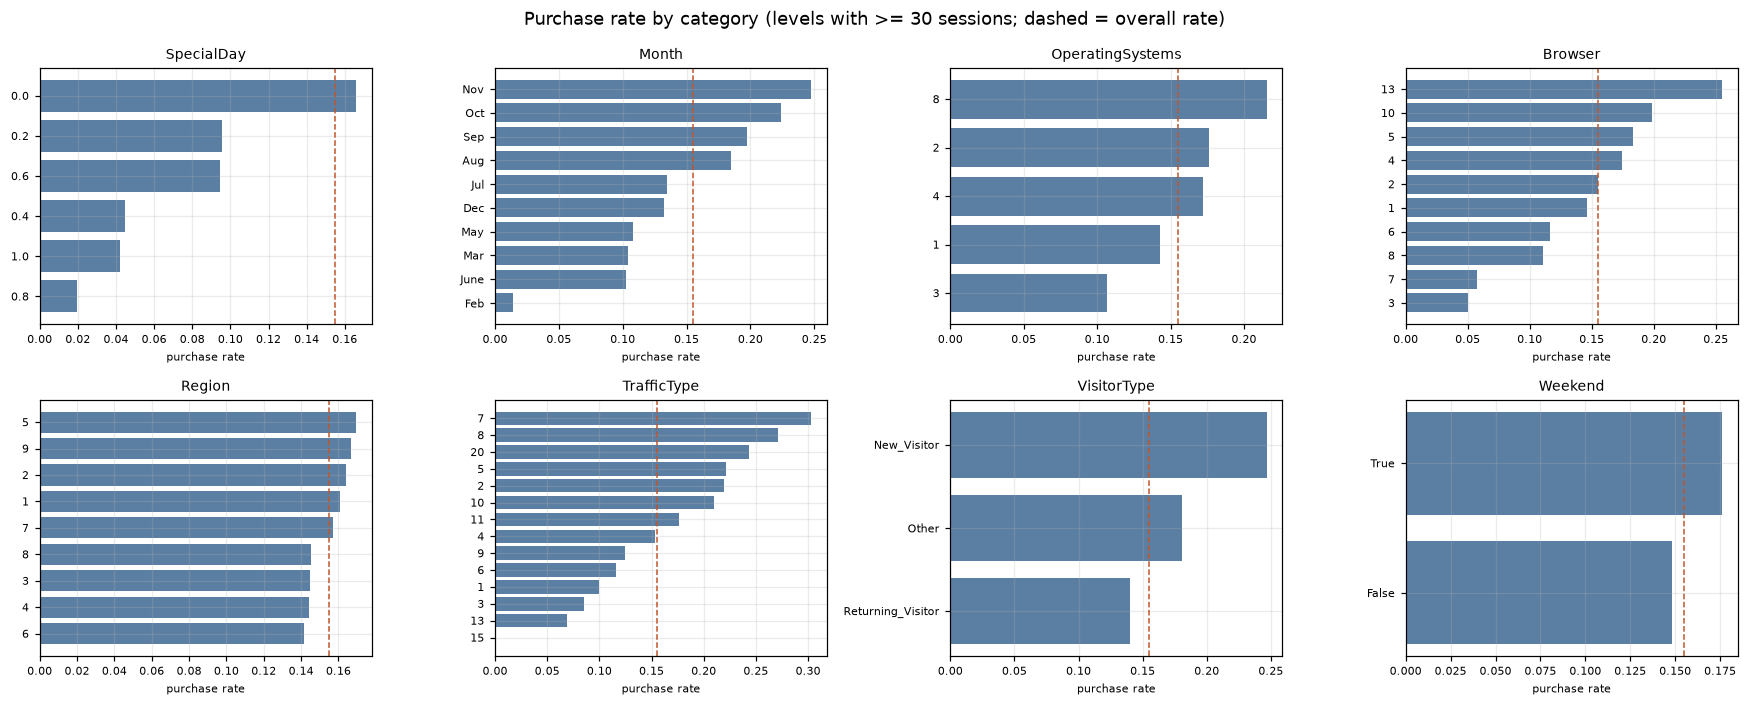

,levels,chi2,dof,p,Cramer's V,highest-rate level,its rate,lowest-rate level,its rate
feature,,,,,,,,,
TrafficType,20,295.1583,19,1.9627e-51,0.1787,7,0.3030,15,0.0000
Month,10,270.5537,9,4.5180e-53,0.1711,Nov,0.2476,Feb,0.0142
VisitorType,3,95.5003,2,1.8297e-21,0.1016,New_Visitor,0.2466,Returning_Visitor,0.1398
SpecialDay,6,82.4562,5,2.5687e-16,0.0944,0.0,0.1658,0.8,0.0196
OperatingSystems,8,56.0728,7,9.1348e-10,0.0779,8,0.2154,3,0.1068
Browser,13,26.8948,12,8.0011e-03,0.0539,13,0.2549,3,0.0506
Weekend,2,9.3238,1,2.2620e-03,0.0318,True,0.1760,False,0.1484
Region,9,5.4993,8,7.0312e-01,0.0244,5,0.1694,6,0.1414


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
rows = []
for ax, c in zip(axes.ravel(), CAT):
    g = pd.DataFrame({"v": Xtr[c], "y": ytr}).groupby("v")["y"].agg(["mean", "size"])
    g = g[g["size"] >= 30].sort_values("mean")
    ax.barh(g.index.astype(str), g["mean"], color="#5b7fa3")
    ax.axvline(rate, color="#c0562c", ls="--", lw=1)
    ax.set_title(c, fontsize=9); ax.tick_params(labelsize=7); ax.set_xlabel("purchase rate", fontsize=7)
    ct = pd.crosstab(Xtr[c], ytr)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append({"feature": c, "levels": Xtr[c].nunique(), "chi2": chi2, "dof": dof, "p": p,
                 "Cramer's V": np.sqrt(chi2 / len(Xtr)),
                 "highest-rate level": str(g["mean"].idxmax()), "its rate": g["mean"].max(),
                 "lowest-rate level": str(g["mean"].idxmin()), "its rate ": g["mean"].min()})
plt.suptitle("Purchase rate by category (levels with >= 30 sessions; dashed = overall rate)")
plt.tight_layout(); plt.show()
EDA_CAT = pd.DataFrame(rows).set_index("feature").sort_values("Cramer's V", ascending=False)
display(EDA_CAT)

**What it tells us.** Traffic source (V = 0.18) and month (V = 0.17) are the strongest categorical signals: November converts at 24.8%, February at 1.4%. New visitors convert more than returning ones (24.7% vs 14.0%). Sessions close to a holiday convert less (SpecialDay 0.8: 2.0% vs 16.6%). Region shows no association (p = 0.70).
**Real-world meaning.** Support effort pays off most in the November peak and on new visitors. The pre-holiday dip suggests people research gifts early and buy later, but that is a hypothesis this data cannot confirm.

### 2.5 Data quality
**Purpose.** Check for problems the summary tables would hide: duplicate sessions, gaps in coverage, and
measurement artefacts. **Method.** Duplicates within training; identical feature rows shared between training
and test, checked on **features only**, so no test labels are looked at; the months covered; and page counts
that disagree with their durations.

In [7]:
dup_tr = Xtr.duplicated(keep=False)
print(f"training sessions that exactly duplicate another: {int(Xtr.duplicated().sum())} extra copies "
      f"({int(dup_tr.sum())} rows involved)")
d_ = Xtr[dup_tr]
print(f"  of these, ProductRelated_Duration = 0: {(d_['ProductRelated_Duration'] == 0).mean():.0%} | "
      f"ExitRates = 0.2: {(d_['ExitRates'] == 0.2).mean():.0%}")
key_ = lambda f: f.astype(str).agg("|".join, axis=1)
twins = key_(Xte).isin(set(key_(Xtr)))
print(f"test sessions whose features exactly match a training session: {int(twins.sum())} of {len(Xte):,} ({twins.mean():.1%})")
ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
seen_ = set(Xtr["Month"]) | set(Xte["Month"])
print("months absent from the whole dataset:", [m for m in ORDER if m not in seen_])
display(pd.DataFrame([{"page type": a, "pages > 0 but duration = 0": int(((Xtr[a] > 0) & (Xtr[b] == 0)).sum()),
                       "pages = 0 but duration > 0": int(((Xtr[a] == 0) & (Xtr[b] > 0)).sum())}
                      for a, b in [("Administrative", "Administrative_Duration"),
                                   ("Informational", "Informational_Duration"),
                                   ("ProductRelated", "ProductRelated_Duration")]]).set_index("page type"))

training sessions that exactly duplicate another: 81 extra copies (136 rows involved)
  of these, ProductRelated_Duration = 0: 100% | ExitRates = 0.2: 100%


test sessions whose features exactly match a training session: 38 of 3,083 (1.2%)
months absent from the whole dataset: ['Jan', 'Apr']


,pages > 0 but duration = 0,pages = 0 but duration > 0
page type,,
Administrative,90,0
Informational,176,0
ProductRelated,545,0


**What it tells us.** Three findings.
- **Duplicates.** 81 training sessions exactly copy another (136 rows involved). Every one is a single-page bounce: no time on product pages and an exit rate of 0.2. These look like genuine repeat visits rather than recording errors, so they are kept. 38 test sessions (1.2%) have an identical twin in training. They are easy cases, so they flatter the held-out result slightly (§17).
- **Coverage.** January and April are missing from the whole dataset. Seasonality is only partly observed, and the model has never seen those months.
- **Measurement.** 545 training sessions viewed product pages yet recorded 0 seconds on them (90 administrative, 176 informational); the reverse never happens. That is a Google Analytics artefact: it cannot time the last page of a visit. So a zero duration does not always mean no engagement, and durations are biased downward.

**Real-world meaning.** None of these justifies changing the analysis, but each one limits how far the numbers can be trusted.

## Modelling machinery (used by every later step)

**Leakage-free pipeline.** Every transformation — imputation, the shape transforms of Stage B,
polynomial terms, scaling, one-hot encoding, and resampling — sits *inside* a scikit-learn `Pipeline`.
Cross-validation therefore refits each of them on every training fold and applies them to that fold's
validation rows only. No fold ever sees statistics computed from its own validation data.

**Evaluation.** `rcv` scores a pipeline on the same 25 folds every time, so any two variants can be
compared fold by fold. `record` logs each variant — including failures — into the results ledger (§11).

**Why repeated 5-fold CV.** LOOCV has almost no bias but high variance, since its training sets are nearly identical,
and it cannot be used here at all: AUC is undefined on a one-session fold. 10-fold CV trains on more data (less
bias) at twice the cost. Repeating 5-fold five times keeps the cost moderate and averages out how the folds happen
to be split, which gives a steadier estimate for fold-by-fold comparisons. Appendix A9 measures the three schemes
on the final model.

In [8]:
def split_view(cols):
    return [c for c in cols if c in NUM], [c for c in cols if c in CAT]

def cat_pipe():
    return Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                     ("oh", OneHotEncoder(drop="if_binary", handle_unknown="infrequent_if_exist",
                                          min_frequency=0.005, sparse_output=False))])

def add_domain(X):
    X = X.copy()
    X["time_per_product_page"] = X["ProductRelated_Duration"] / (X["ProductRelated"] + 1)
    X["time_per_admin_page"]   = X["Administrative_Duration"] / (X["Administrative"] + 1)
    X["total_pages"]    = X["Administrative"] + X["Informational"] + X["ProductRelated"]
    X["total_duration"] = (X["Administrative_Duration"] + X["Informational_Duration"]
                           + X["ProductRelated_Duration"])
    X["product_page_share"] = X["ProductRelated"] / (X["total_pages"] + 1)
    return X
DOMAIN = ["time_per_product_page", "time_per_admin_page", "total_pages", "total_duration",
          "product_page_share"]

def add_cross(X):
    X = X.copy(); X["Visitor_x_Month"] = X["VisitorType"] + "_" + X["Month"]; return X

def zeroind(num_cols):
    """log1p of every feature, plus a 0/1 'any activity' flag for zero-heavy ones."""
    idx = [i for i, c in enumerate(num_cols) if c in ZERO_HEAVY]
    names = lambda tf, inp: np.r_[[f"log1p({n})" for n in inp], [f"any({inp[i]})" for i in idx]]
    return FunctionTransformer(
        lambda A: np.hstack([np.log1p(np.asarray(A, float)), (np.asarray(A, float)[:, idx] > 0) * 1.0]),
        feature_names_out=names)

def tf_step(transform, num_cols):
    return {"none": "passthrough",
            "log1p": FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
            "yeojohnson": PowerTransformer(method="yeo-johnson", standardize=False),
            "quantile": QuantileTransformer(output_distribution="normal", n_quantiles=1000,
                                            random_state=SEED)}.get(transform) \
           or zeroind(num_cols)

def make_pre(transform="none", poly=1, inter_only=False, domain=False, cross=False,
             num=None, cat=None):
    """Every preprocessing step lives here, so a Pipeline refits it inside each training fold."""
    num = list(NUMM if num is None else num) + (DOMAIN if domain else [])
    cat = list(CAT if cat is None else cat) + (["Visitor_x_Month"] if cross else [])
    nsteps = [("imp", SimpleImputer(strategy="median")), ("tf", tf_step(transform, num))]
    if poly > 1:
        nsteps.append(("poly", PolynomialFeatures(poly, interaction_only=inter_only, include_bias=False)))
    nsteps.append(("sc", StandardScaler()))
    parts = ([("num", Pipeline(nsteps), num)] if num else []) + ([("cat", cat_pipe(), cat)] if cat else [])
    steps = ([("dom", FunctionTransformer(add_domain))] if domain else []) + \
            ([("cross", FunctionTransformer(add_cross))] if cross else [])
    return steps + [("ct", ColumnTransformer(parts, remainder="drop"))]

def build(clf, sampler=None, **pre):
    steps = make_pre(**pre)
    if sampler is not None:                   # imblearn resamples the TRAINING fold only
        return ImbPipeline([("smp", sampler)] + steps + [("clf", clf)])
    return Pipeline(steps + [("clf", clf)])

def rcv(p):  return cross_val_score(p, Xtr, ytr, cv=rskf, scoring="roc_auc", n_jobs=-1)
def cv5(p):
    try:    return cross_val_score(p, Xtr, ytr, cv=skf, scoring="roc_auc", n_jobs=-1)
    except Exception: return np.full(5, np.nan)          # a setting that cannot be fitted scores NaN
def oof(p):  return cross_val_predict(p, Xtr, ytr, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]

def corrected_ttest(a, b):
    """Nadeau & Bengio (2003). Repeated-CV folds share training rows, so a plain paired t-test
    understates the variance. The correction inflates it by n_test/n_train (= 0.25 here)."""
    d = np.asarray(a) - np.asarray(b); J = len(d)
    se = np.sqrt((1 / J + 0.25) * d.var(ddof=1))
    t = d.mean() / se if se > 0 else 0.0
    return d.mean(), 2 * stats.t.sf(abs(t), J - 1)

LEDGER, SCORES, CONF = [], {}, {}
def record(stage, variant, model, clf, pre, ref=None, sampler=None, note=""):
    """Score one variant on the shared 25 folds and log it. A variant that cannot be fitted is
    logged as FAILED with the reason, never silently dropped."""
    key = (stage, variant, model)
    try:
        s = rcv(build(clone(clf), sampler=None if sampler is None else clone(sampler), **pre))
    except Exception as e:
        s = np.full(25, np.nan)
        note = (note + " | " if note else "") + "all fits failed: " + str(e).strip().splitlines()[-1][:90]
    SCORES[key], CONF[key] = s, dict(clf=clf, pre=pre, sampler=sampler)
    row = {"stage": stage, "variant": variant, "model": model, "CV AUC": s.mean(), "SD": s.std(ddof=1)}
    if np.isnan(s).all():
        row["verdict"] = "FAILED TO FIT"
    elif ref is not None:
        d, p = corrected_ttest(s, SCORES[ref])
        row.update({"vs": f"{ref[0]}:{ref[1]}", "Δ AUC": d, "p": p,
                    "verdict": ("GAIN" if d > 0 else "LOSS") if p < 0.05 else "no sig. change"})
    row["note"] = note
    LEDGER.append(row)
    return s

def pipe_of(key):
    c = CONF[key]
    return build(clone(c["clf"]), sampler=None if c["sampler"] is None else clone(c["sampler"]), **c["pre"])

def carried(model, stage, prev):
    """Parsimony rule: adopt a stage's variant only if it is a significant GAIN over the
    configuration currently carried forward (prev). Otherwise keep the simpler prev."""
    elig = [r for r in LEDGER if r["model"] == model and r["stage"] == stage and r.get("verdict") == "GAIN"
            and r.get("vs") == f"{prev[0]}:{prev[1]}"]
    return prev if not elig else (stage, max(elig, key=lambda r: r["CV AUC"])["variant"], model)

def best_key(model, stages):
    ks = [k for k in SCORES if k[2] == model and k[0] in stages and np.isfinite(SCORES[k].mean())]
    return max(ks, key=lambda k: SCORES[k].mean())

def rates(y, p, t):
    tn, fp, fn, tp = confusion_matrix(y, (np.asarray(p) >= t).astype(int), labels=[0, 1]).ravel()
    return dict(TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp),
                sens=tp / (tp + fn) if tp + fn else np.nan, spec=tn / (tn + fp) if tn + fp else np.nan)

def cost_curve(y, p, ratio=COST):
    ts = np.linspace(0.005, 0.995, 199); y = np.asarray(y); P, N = (y == 1).sum(), (y == 0).sum()
    c, se, sp = [], [], []
    for t in ts:
        pr = p >= t; tp = (pr & (y == 1)).sum(); fp = (pr & (y == 0)).sum()
        c.append(((P - tp) * ratio + fp) / len(y)); se.append(tp / P); sp.append((N - fp) / N)
    return ts, np.array(c), np.array(se), np.array(sp)

def sens_at_spec(y, p, spec):
    fpr, tpr, _ = roc_curve(y, p); ok = fpr <= 1 - spec
    return tpr[ok].max() if ok.any() else 0.0

def wilson(k, n):
    if not n: return (np.nan, np.nan)
    z = 1.959963985; ph = k / n; d = 1 + z * z / n
    c = (ph + z * z / (2 * n)) / d; h = z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / d
    return max(0., c - h), min(1., c + h)

NUMM = [c for c in NUM if c != "PageValues"]        # modelling set after §3 (set below)
print("helpers ready")

helpers ready


## §3 Leakage audit

**Purpose.** Find any feature that encodes the outcome rather than predicting it. **Method.** A
univariate screen: each feature's AUC on its own. A very high score is not proof of leakage — a
genuinely strong predictor also scores high — but it tells us where to look.

In [9]:
lr = LogisticRegression(max_iter=5000)
rows = []
for c in NUM + CAT:
    if c in NUM:
        a = roc_auc_score(ytr, Xtr[c]); a = max(a, 1 - a)
    else:
        p = cross_val_predict(Pipeline([("ct", ColumnTransformer([("c", cat_pipe(), [c])])),
                                        ("clf", clone(lr))]), Xtr, ytr, cv=skf,
                              method="predict_proba", n_jobs=-1)[:, 1]
        a = roc_auc_score(ytr, p)
    rows.append({"feature": c, "univariate AUC": a})
SCREEN = pd.DataFrame(rows).sort_values("univariate AUC", ascending=False).set_index("feature")
display(SCREEN.T.round(3))

feature,PageValues,ExitRates,ProductRelated_Duration,ProductRelated,Administrative,Administrative_Duration,TrafficType,BounceRates,Month,Informational,Informational_Duration,OperatingSystems,VisitorType,SpecialDay,Browser,Weekend,Region
univariate AUC,0.87,0.714,0.678,0.664,0.633,0.632,0.621,0.619,0.613,0.566,0.563,0.543,0.541,0.538,0.517,0.515,0.502


**What it tells us.** `PageValues` stands apart at 0.87; the next strongest feature, `ExitRates`, reaches 0.71. One feature that far ahead of the rest warrants investigation.

**The `PageValues` question.** `PageValues` is a Google Analytics figure: the average value of the
pages a visitor viewed, where page value is assigned *from sessions that completed a transaction*.
A buying session's own purchase therefore raises the value of the pages it visited. **Method.** Price
it rather than assert it: CV AUC with and without it. The difference is the **leakage premium**.

In [10]:
with_pv    = cv5(build(clone(lr), num=NUM))
without_pv = cv5(build(clone(lr), num=NUMM))
PREMIUM = with_pv.mean() - without_pv.mean()
print(f"5-fold CV AUC with PageValues    : {with_pv.mean():.4f}  (SD {with_pv.std(ddof=1):.4f})")
print(f"5-fold CV AUC without PageValues : {without_pv.mean():.4f}  (SD {without_pv.std(ddof=1):.4f})")
print(f"leakage premium                  : {PREMIUM:.4f}")
pv_share = pd.crosstab(Xtr["PageValues"] > 0, ytr, normalize="columns")
print(f"\nshare of sessions with PageValues > 0:  buyers {pv_share.loc[True, 1]:.1%}  |  "
      f"non-buyers {pv_share.loc[True, 0]:.1%}")
print(f"purchase rate when PageValues = 0: {ytr[Xtr['PageValues'] == 0].mean():.2%}  |  "
      f"when > 0: {ytr[Xtr['PageValues'] > 0].mean():.2%}")
Xtr, Xte = Xtr.drop(columns="PageValues"), Xte.drop(columns="PageValues")
print(f"\nPageValues removed from train and test. Modelling set: {len(NUMM)} numeric + {len(CAT)} categorical "
      f"= {len(NUMM) + len(CAT)} predictors")

5-fold CV AUC with PageValues    : 0.8943  (SD 0.0069)
5-fold CV AUC without PageValues : 0.7530  (SD 0.0218)
leakage premium                  : 0.1413

share of sessions with PageValues > 0:  buyers 81.8%  |  non-buyers 11.4%
purchase rate when PageValues = 0: 3.63%  |  when > 0: 56.85%

PageValues removed from train and test. Modelling set: 8 numeric + 8 categorical = 16 predictors


**What it tells us.** CV AUC is 0.894 with `PageValues` and 0.753 without it, a **leakage premium of 0.141**. 81.8% of buyers have non-zero `PageValues`, against 11.4% of non-buyers, and the purchase rate jumps from 3.6% to 56.9% once it is non-zero. That is the signature of a variable that partly records the outcome. **Decision: drop it.**
**Real-world meaning.** A model built on it would look excellent in testing and disappoint in deployment.

## §4 Assumption diagnostics

The four methods assume different things. Instead of asserting which assumptions fail, we test each.
With ~9,000 rows, formal tests reject even trivial departures, so every test is paired with a
**magnitude** (skew, variance ratio, correlation) and a **plot**.

### 4.1 Normality within each class
**Purpose.** Gaussian Naive Bayes, LDA and QDA all model each class as normally distributed.
**Method.** D'Agostino–Pearson K² test per feature per class (combines skew and kurtosis; Shapiro–Wilk
is unreliable above n ≈ 5,000), plus Q-Q plots.

n     skew  excess kurtosis  D'Agostino K2            p
feature                 class                                                                  
Administrative          no purchase  7816   2.1587           6.0047      3504.9000   0.0000e+00
                        purchase     1431   1.3750           1.9015       335.6450   1.3050e-73
Administrative_Duration no purchase  7816   6.2917          63.2884      9312.4725   0.0000e+00
                        purchase     1431   3.8083          20.7564      1187.3375  1.4891e-258
Informational           no purchase  7816   4.6218          38.1808      7575.8367   0.0000e+00
                        purchase     1431   2.8029          10.2627       878.7521  1.5185e-191
Informational_Duration  no purchase  7816   8.6904         100.4742     11238.7109   0.0000e+00
                        purchase     1431   4.8719          30.8083      1432.0496  1.0824e-311
ProductRelated          no purchase  7816   4.7998          42.8264      7819.6158   0.0000e+00
                        purchase     1431   3.2533          15.4262      1034.3716  2.4494e-225
ProductRelated_Duration no purchase  7816  10.0831         243.1471     12547.5926   0.0000e+00
                        purchase     1431   3.0887          14.0219       986.1749  7.1588e-215
BounceRates             no purchase  7816   2.6480           5.8793      4095.3200   0.0000e+00
                        purchase     1431   8.7199         121.9877      2134.1032   0.0000e+00
ExitRates               no purchase  7816   1.9201           2.8881      2739.4362   0.0000e+00
                        purchase     1431   3.6167          28.1279      1196.2217  1.7529e-260

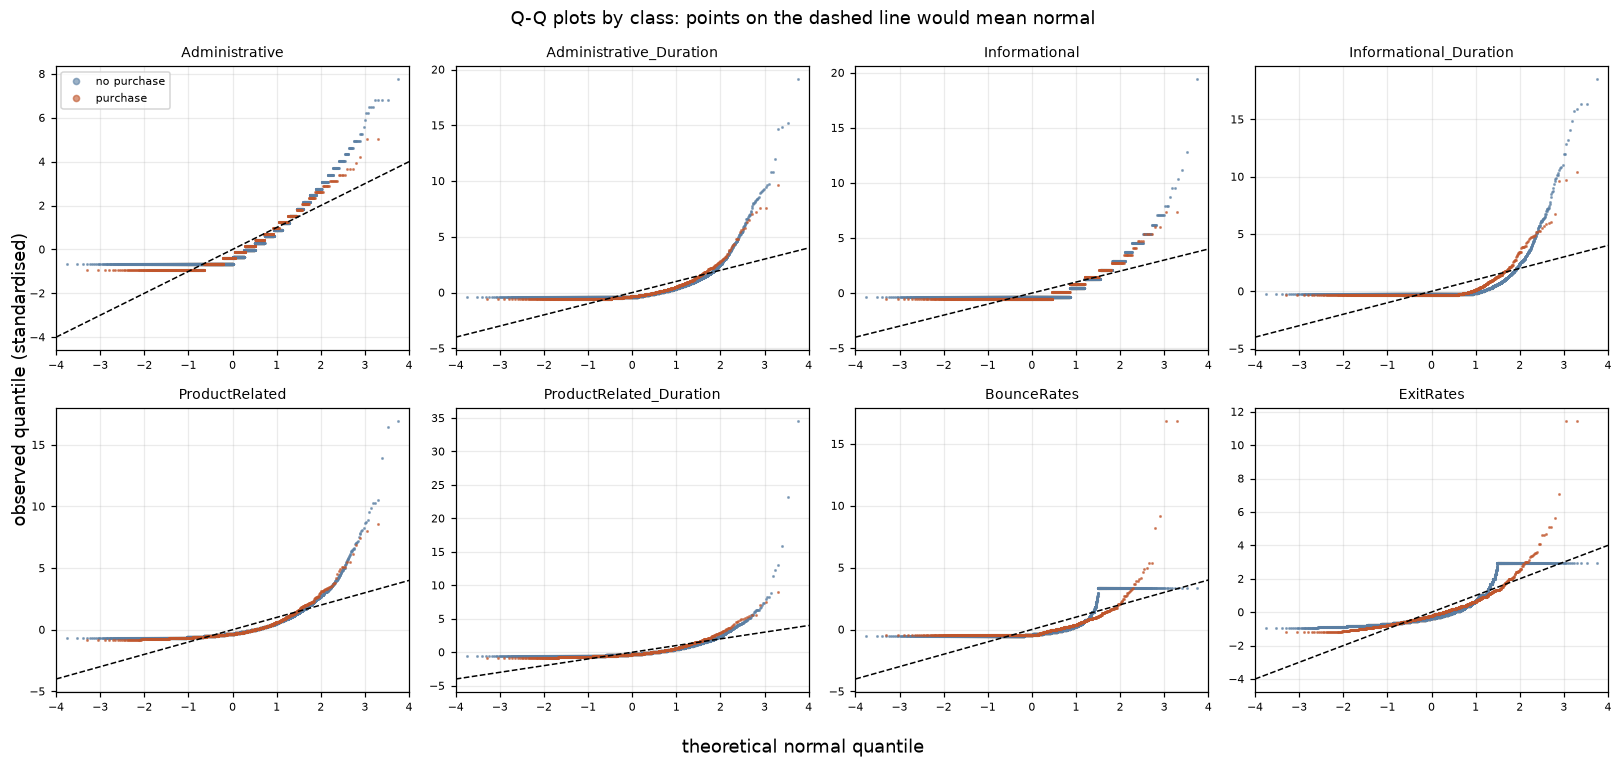

features with |skew| > 1 in BOTH classes: 8 of 8
largest K2 p-value across all 16 tests: 1.31e-73


In [11]:
rows = []
for c in NUMM:
    for k, lab in [(0, "no purchase"), (1, "purchase")]:
        v = Xtr.loc[ytr == k, c].values
        k2, p = stats.normaltest(v)
        rows.append({"feature": c, "class": lab, "n": len(v), "skew": stats.skew(v),
                     "excess kurtosis": stats.kurtosis(v), "D'Agostino K2": k2, "p": p})
NORM = pd.DataFrame(rows).set_index(["feature", "class"]); display(NORM)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, c in zip(axes.ravel(), NUMM):
    for k, col, lab in [(0, "#5b7fa3", "no purchase"), (1, "#c0562c", "purchase")]:
        v = Xtr.loc[ytr == k, c].values; z = (v - v.mean()) / v.std()
        (osm, osr), _ = stats.probplot(z, dist="norm")
        ax.plot(osm, osr, ".", ms=2, color=col, label=lab, alpha=.6)
    ax.plot([-4, 4], [-4, 4], "k--", lw=1); ax.set_xlim(-4, 4)
    ax.set_title(c, fontsize=9); ax.tick_params(labelsize=7)
axes[0, 0].legend(fontsize=7, markerscale=4)
fig.supxlabel("theoretical normal quantile"); fig.supylabel("observed quantile (standardised)")
plt.suptitle("Q-Q plots by class: points on the dashed line would mean normal")
plt.tight_layout(); plt.show()
print(f"features with |skew| > 1 in BOTH classes: "
      f"{int((NORM['skew'].abs() > 1).groupby('feature').all().sum())} of {len(NUMM)}")
print(f"largest K2 p-value across all 16 tests: {NORM['p'].max():.2e}")

**What it tells us.** Normality fails decisively. All 8 features have |skew| > 1 in both classes, excess kurtosis reaches 243, and the largest K² p-value is 10⁻⁷³. The Q-Q plots bend sharply away from the line in the upper tail. NB, LDA and QDA are therefore misspecified on raw data, which motivates Stage B.

### 4.2 Equal covariance across classes
**Purpose.** LDA assumes both classes share one covariance matrix, which is what makes its boundary a
straight line. QDA drops this assumption. **Method.** Box's M test (all features jointly); the
Brown–Forsythe test per feature (a robust Levene test); the two classes' correlation matrices side by side.

Box's M = 4,660.9   chi2 = 4,651.5   df = 36   p = 0.00e+00


,SD (no),SD (buy),SD ratio buy/no,Brown-Forsythe W,p
feature,,,,,
Administrative,3.2072,3.6866,1.1495,53.2844,3.1242e-13
Administrative_Duration,173.7970,203.4822,1.1708,52.6516,4.3038e-13
Informational,1.2128,1.5278,1.2597,84.1131,5.6768e-20
Informational_Duration,136.1219,165.1330,1.2131,41.7313,1.1000e-10
ProductRelated,39.9617,56.6387,1.4173,96.4178,1.2002e-22
ProductRelated_Duration,1820.9621,2210.2372,1.2138,70.3139,5.7995e-17
BounceRates,0.0521,0.0116,0.2226,231.5470,1.1552e-51
ExitRates,0.0514,0.0158,0.3078,345.9455,7.7524e-76


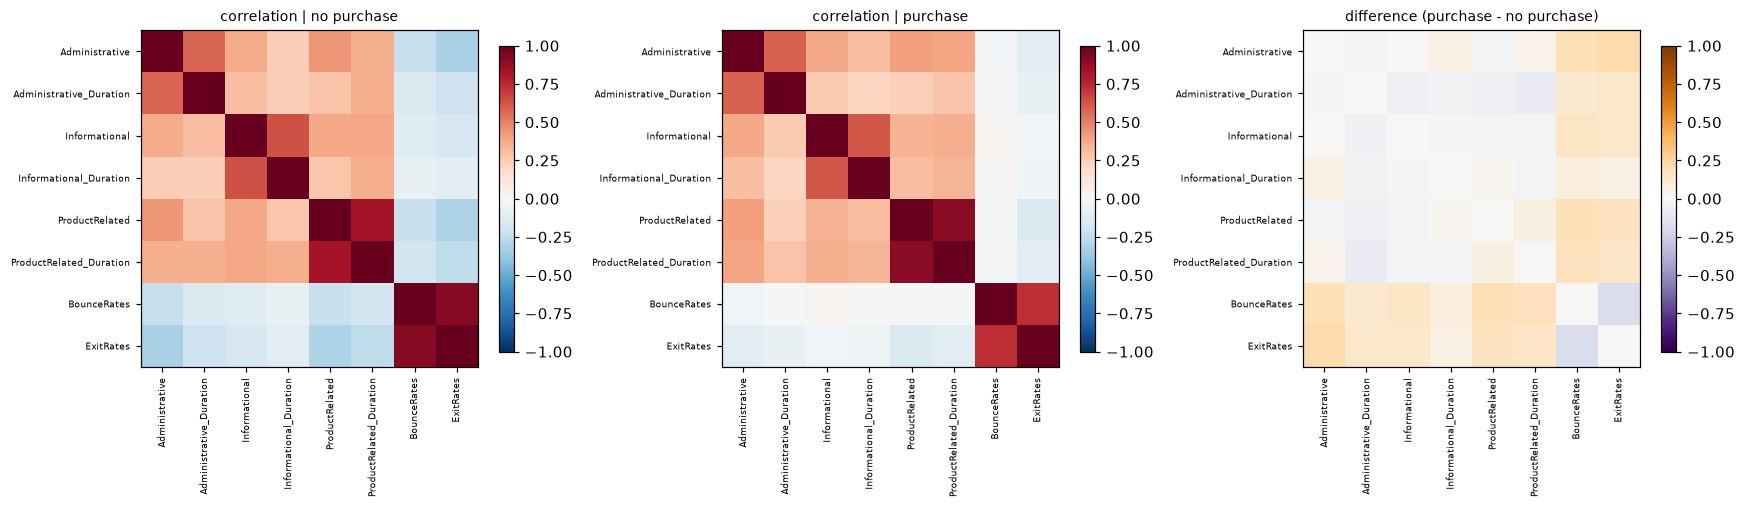

largest absolute change in any correlation between classes: 0.222


In [12]:
def box_m(groups):
    """Box's M test for equality of covariance matrices (chi-square approximation)."""
    k, p = len(groups), groups[0].shape[1]
    ns = np.array([len(g) for g in groups]); N = ns.sum()
    S = [np.cov(g, rowvar=False) for g in groups]
    Sp = sum((n - 1) * s for n, s in zip(ns, S)) / (N - k)
    M = (N - k) * np.linalg.slogdet(Sp)[1] - sum((n - 1) * np.linalg.slogdet(s)[1] for n, s in zip(ns, S))
    c = (2 * p * p + 3 * p - 1) / (6 * (p + 1) * (k - 1)) * (sum(1 / (n - 1) for n in ns) - 1 / (N - k))
    df_ = p * (p + 1) * (k - 1) / 2
    return M, M * (1 - c), df_, stats.chi2.sf(M * (1 - c), df_)

G = [Xtr.loc[ytr == k, NUMM].values for k in (0, 1)]
M, chi, dfm, pm = box_m(G)
print(f"Box's M = {M:,.1f}   chi2 = {chi:,.1f}   df = {dfm:.0f}   p = {pm:.2e}")
rows = []
for c in NUMM:
    v0, v1 = Xtr.loc[ytr == 0, c], Xtr.loc[ytr == 1, c]
    W, p = stats.levene(v0, v1, center="median")
    rows.append({"feature": c, "SD (no)": v0.std(), "SD (buy)": v1.std(), "SD ratio buy/no": v1.std() / v0.std(),
                 "Brown-Forsythe W": W, "p": p})
LEV = pd.DataFrame(rows).set_index("feature"); display(LEV)

C0 = Xtr.loc[ytr == 0, NUMM].corr().values; C1 = Xtr.loc[ytr == 1, NUMM].corr().values
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, Cm, t, cm_ in [(ax[0], C0, "correlation | no purchase", "RdBu_r"), (ax[1], C1, "correlation | purchase", "RdBu_r"),
                      (ax[2], C1 - C0, "difference (purchase - no purchase)", "PuOr_r")]:
    im = a.imshow(Cm, vmin=-1, vmax=1, cmap=cm_)
    a.set_xticks(range(len(NUMM))); a.set_xticklabels(NUMM, rotation=90, fontsize=6)
    a.set_yticks(range(len(NUMM))); a.set_yticklabels(NUMM, fontsize=6); a.set_title(t, fontsize=9)
    a.grid(False); fig.colorbar(im, ax=a, shrink=.75)
plt.tight_layout(); plt.show()
print(f"largest absolute change in any correlation between classes: {np.abs(C1 - C0).max():.3f}")

**What it tells us.** Box's M gives χ² = 4,651 on 36 df (p ≈ 0), and all 8 features have unequal variances. The largest gaps are in `BounceRates` and `ExitRates`, where buyers' spread is only 22% and 31% of non-buyers'. Equal covariance fails, so QDA is a legitimate question for Stage C. (Box's M is itself sensitive to non-normality, which is why the per-feature evidence is shown too.)
**Real-world meaning.** Buyers behave more consistently than browsers.

### 4.3 Independence within each class
**Purpose.** Naive Bayes assumes features are independent *given the class*. **Method.** Correlation
matrices computed separately for buyers and non-buyers — the quantity the assumption is actually about.

In [13]:
rows = []
for k, lab in [(0, "no purchase"), (1, "purchase")]:
    Cm = Xtr.loc[ytr == k, NUMM].corr()
    off = Cm.where(~np.eye(len(NUMM), dtype=bool)).abs()
    pairs = off.stack().sort_values(ascending=False)
    pairs = pairs[~pairs.index.map(lambda t: tuple(sorted(t))).duplicated()]
    rows.append({"class": lab, "mean |r|": off.stack().mean(), "pairs with |r| > 0.5": int((pairs > .5).sum()),
                 "top pair": f"{pairs.index[0][0]} ~ {pairs.index[0][1]}", "top |r|": pairs.iloc[0]})
IND = pd.DataFrame(rows).set_index("class"); display(IND)
print("Naive Bayes assumes these within-class correlations are all zero.")

,mean |r|,pairs with |r| > 0.5,top pair,top |r|
class,,,,
no purchase,0.3336,4,ExitRates ~ BounceRates,0.9135
purchase,0.2608,4,ProductRelated_Duration ~ ProductRelated,0.8991


Naive Bayes assumes these within-class correlations are all zero.


**What it tells us.** Within-class mean |r| is 0.33 (non-buyers) and 0.26 (buyers), with pairs as high as 0.91 (`ExitRates` ~ `BounceRates`). Naive Bayes counts each of these as independent evidence, which predicts it will rank worst. Stage A confirms this.

### 4.4 Multicollinearity
**Purpose.** Strongly correlated predictors make logistic coefficients unstable and hard to interpret,
though not necessarily less predictive. **Method.** Variance inflation factor (VIF); above 5 is a common warning level.

In [14]:
Z = StandardScaler().fit_transform(Xtr[NUMM])
Zc = sm.add_constant(Z)
VIF = pd.Series([variance_inflation_factor(Zc, i + 1) for i in range(len(NUMM))], index=NUMM, name="VIF")
display(VIF.to_frame().T.round(2))
print(f"features with VIF > 5: {list(VIF[VIF > 5].index) or 'none'}")

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates
VIF,1.93,1.67,1.87,1.74,4.2,4.12,6.2,6.67


features with VIF > 5: ['BounceRates', 'ExitRates']


**What it tells us.** `BounceRates` (6.2) and `ExitRates` (6.7) exceed 5, and everything else is at or below 4.2. The collinearity is moderate: it matters when interpreting those two coefficients, and ridge regularisation (Stage D) is the standard remedy.

### 4.5 Linearity of the log-odds
**Purpose.** Logistic regression assumes the log-odds of purchase change linearly with each feature.
**Method.** Empirical log-odds by decile; the Box–Tidwell test, which adds an x·ln(x) term — a
significant term means the relationship is curved.

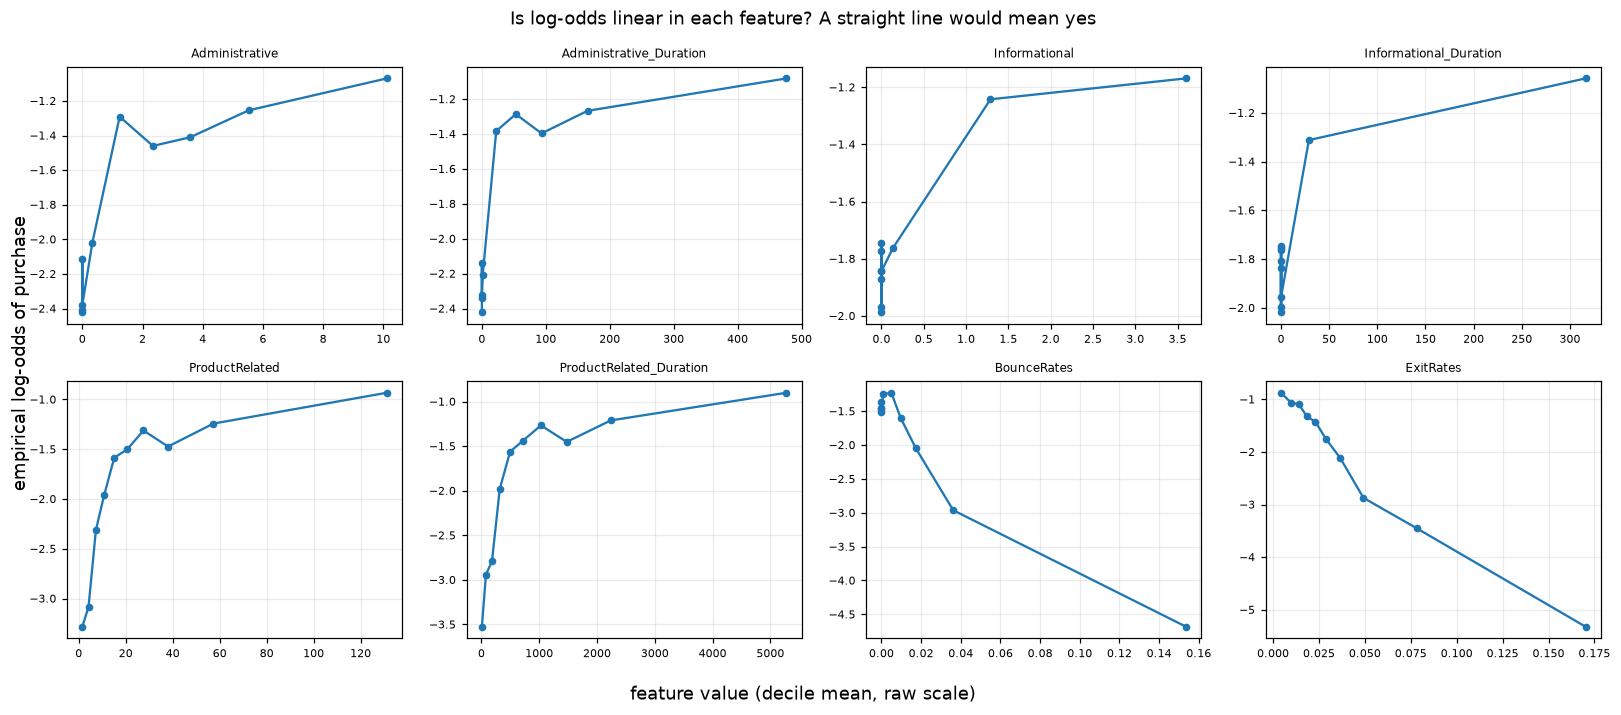

,Box-Tidwell p (raw),Box-Tidwell p (log1p)
feature,,
Administrative,3.4497e-19,4.2028e-09
Administrative_Duration,8.3187e-26,3.5575e-04
Informational,4.8717e-07,2.0125e-03
Informational_Duration,7.7345e-13,1.5894e-01
ProductRelated,3.2859e-26,1.9306e-07
ProductRelated_Duration,1.2217e-32,7.0909e-01
BounceRates,4.5689e-04,3.8486e-03
ExitRates,2.4474e-03,2.1314e-02


In [15]:
def emp_logit_plot(ax, x, y, title, q=10):
    b = pd.qcut(x.rank(method="first"), q, labels=False)
    g = pd.DataFrame({"x": x, "y": y, "b": b}).groupby("b").agg(x=("x", "mean"), k=("y", "sum"), n=("y", "size"))
    ax.plot(g["x"], np.log((g["k"] + .5) / (g["n"] - g["k"] + .5)), "o-", ms=4)
    ax.set_title(title, fontsize=8); ax.tick_params(labelsize=7)

def box_tidwell_p(x, y):
    z = x - x.min() + 1
    X = sm.add_constant(np.column_stack([x, z * np.log(z)]))
    try:    return sm.Logit(y, X).fit(disp=0).pvalues[2]
    except Exception: return np.nan

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
bt = []
for ax, c in zip(axes.ravel(), NUMM):
    emp_logit_plot(ax, Xtr[c], ytr, c)
    bt.append({"feature": c, "Box-Tidwell p (raw)": box_tidwell_p(Xtr[c].values, ytr.values),
               "Box-Tidwell p (log1p)": box_tidwell_p(np.log1p(Xtr[c].values), ytr.values)})
fig.supxlabel("feature value (decile mean, raw scale)"); fig.supylabel("empirical log-odds of purchase")
plt.suptitle("Is log-odds linear in each feature? A straight line would mean yes")
plt.tight_layout(); plt.show()
BT = pd.DataFrame(bt).set_index("feature"); display(BT)

**What it tells us.** Every raw feature bends, and Box–Tidwell rejects linearity for all 8 (p ≤ 0.002). After log1p, two features become consistent with linearity (`Informational_Duration` p = 0.16, `ProductRelated_Duration` p = 0.71), and the rest weaken by orders of magnitude. So even logistic regression has a reason to transform.

### 4.6 Summary

In [16]:
SUMMARY = pd.DataFrame([
 {"assumption": "normal within each class", "needed by": "GaussianNB, LDA, QDA",
  "evidence": f"{int((NORM['skew'].abs()>1).groupby('feature').all().sum())}/{len(NUMM)} features |skew|>1 in both classes; all K2 p < {NORM['p'].max():.0e}",
  "holds?": "NO"},
 {"assumption": "equal covariance across classes", "needed by": "LDA",
  "evidence": f"Box's M p = {pm:.1e}; {int((LEV['p']<.05).sum())}/{len(NUMM)} features unequal variance (Brown-Forsythe)",
  "holds?": "NO" if pm < .05 else "yes"},
 {"assumption": "features independent within class", "needed by": "GaussianNB",
  "evidence": f"within-class mean |r| {IND['mean |r|'].min():.2f}-{IND['mean |r|'].max():.2f}; max pair |r| {IND['top |r|'].max():.2f}",
  "holds?": "NO"},
 {"assumption": "no severe multicollinearity", "needed by": "Logistic (coefficient stability)",
  "evidence": f"{int((VIF>5).sum())} features with VIF > 5 (max {VIF.max():.1f})",
  "holds?": "partly" if (VIF > 5).any() else "yes"},
 {"assumption": "log-odds linear in each feature", "needed by": "Logistic",
  "evidence": f"Box-Tidwell rejects linearity for {int((BT['Box-Tidwell p (raw)']<.05).sum())}/{len(NUMM)} raw features",
  "holds?": "NO" if (BT['Box-Tidwell p (raw)'] < .05).sum() > len(NUMM) / 2 else "partly"},
]).set_index("assumption")
display(SUMMARY)

,needed by,evidence,holds?
assumption,,,
normal within each class,"GaussianNB, LDA, QDA",8/8 features |skew|>1 in both classes; all K2 ...,NO
equal covariance across classes,LDA,Box's M p = 0.0e+00; 8/8 features unequal vari...,NO
features independent within class,GaussianNB,within-class mean |r| 0.26-0.33; max pair |r| ...,NO
no severe multicollinearity,Logistic (coefficient stability),2 features with VIF > 5 (max 6.7),partly
log-odds linear in each feature,Logistic,Box-Tidwell rejects linearity for 8/8 raw feat...,NO


**What it tells us.** Four of five assumptions fail outright and the fifth partly. None of the four methods is correctly specified on raw data, and each later stage targets one failure.

## §5 Stage A — Baseline

**Purpose.** A benchmark: the four methods with no transformation and default settings, so every later
change is measured against it. **Method.** 25-fold CV AUC. QDA is the fourth method because it is the
direct test of LDA's equal-covariance assumption (§4.2).

In [17]:
ZERO_HEAVY = [c for c in NUMM + DOMAIN if (add_domain(Xtr)[c] == 0).mean() >= 0.20]
BASE = dict(transform="none")
MODELS = {"Logistic": LogisticRegression(max_iter=5000), "GaussianNB": GaussianNB(),
          "LDA": LDA(), "QDA": QDA(reg_param=0.0)}
for m, clf in MODELS.items():
    record("A", "raw", m, clf, BASE, note="baseline: no transformation, default settings")
display(pd.DataFrame(LEDGER).set_index(["stage", "variant", "model"])[["CV AUC", "SD"]])

CV AUC      SD
stage variant model                     
A     raw     Logistic    0.7517  0.0158
              GaussianNB  0.7043  0.0151
              LDA         0.7407  0.0151
              QDA            NaN     NaN

**What it tells us.** Default QDA could not be fitted at all: every fold failed. The next cell shows why.

**Purpose.** Diagnose why default QDA failed rather than drop it.

In [18]:
M_ = make_pre(**BASE)[-1][1].fit(Xtr).transform(Xtr)
rk = [np.linalg.matrix_rank(np.cov(M_[ytr.values == k], rowvar=False)) for k in (0, 1)]
ev = [np.linalg.eigvalsh(np.cov(M_[ytr.values == k], rowvar=False)).min() for k in (0, 1)]
print(f"design matrix columns after one-hot: {M_.shape[1]}")
print(f"rank of class covariance: no purchase {rk[0]}, purchase {rk[1]}  (full rank would be {M_.shape[1]})")
print(f"smallest eigenvalue: {ev[0]:.2e}, {ev[1]:.2e}")
record("A", "raw, reg_param=0.01", "QDA", QDA(reg_param=0.01), BASE,
       note="minimal ridge so each class covariance is invertible; tuned properly in Stage D")

design matrix columns after one-hot: 65
rank of class covariance: no purchase 58, purchase 58  (full rank would be 65)
smallest eigenvalue: -2.29e-15, -8.85e-16


array([0.69813594, 0.69963953, 0.71948333, 0.73810674, 0.72729733,
       0.70318396, 0.71557422, 0.71269613, 0.7468782 , 0.69154933,
       0.72649697, 0.70353403, 0.73476683, 0.70852404, 0.69586683,
       0.70738469, 0.71503697, 0.72026406, 0.71883459, 0.72046092,
       0.7095197 , 0.72452913, 0.71980547, 0.71348357, 0.6962874 ])

**What it tells us.** After one-hot encoding there are 65 columns, but each class covariance has rank 58: within a class, some dummies are exact combinations of others, so the matrix cannot be inverted. A small ridge (reg_param = 0.01) fixes this and gives AUC 0.715. The value is tuned in Stage D.

**Purpose.** The required per-model evaluation: confusion matrix, sensitivity, specificity, ROC and AUC.
**Method.** 5-fold out-of-fold predictions on the training data at the default threshold 0.5, plus
calibration curves (do predicted probabilities match observed rates?) and the Brier score (mean squared
error of the probabilities; lower is better).

,CV AUC (25-fold),SD,TN,FP,FN,TP,sens,spec,predicted-positive rate,Brier
model,,,,,,,,,,
Logistic,0.7517,0.0158,7769,47,1395,36,0.0252,0.9940,0.0090,0.1176
GaussianNB,0.7043,0.0151,3486,4330,220,1211,0.8463,0.4460,0.5992,0.4523
LDA,0.7407,0.0151,7746,70,1368,63,0.0440,0.9910,0.0144,0.1193
QDA,0.7147,0.0139,4335,3481,318,1113,0.7778,0.5546,0.4968,0.3409


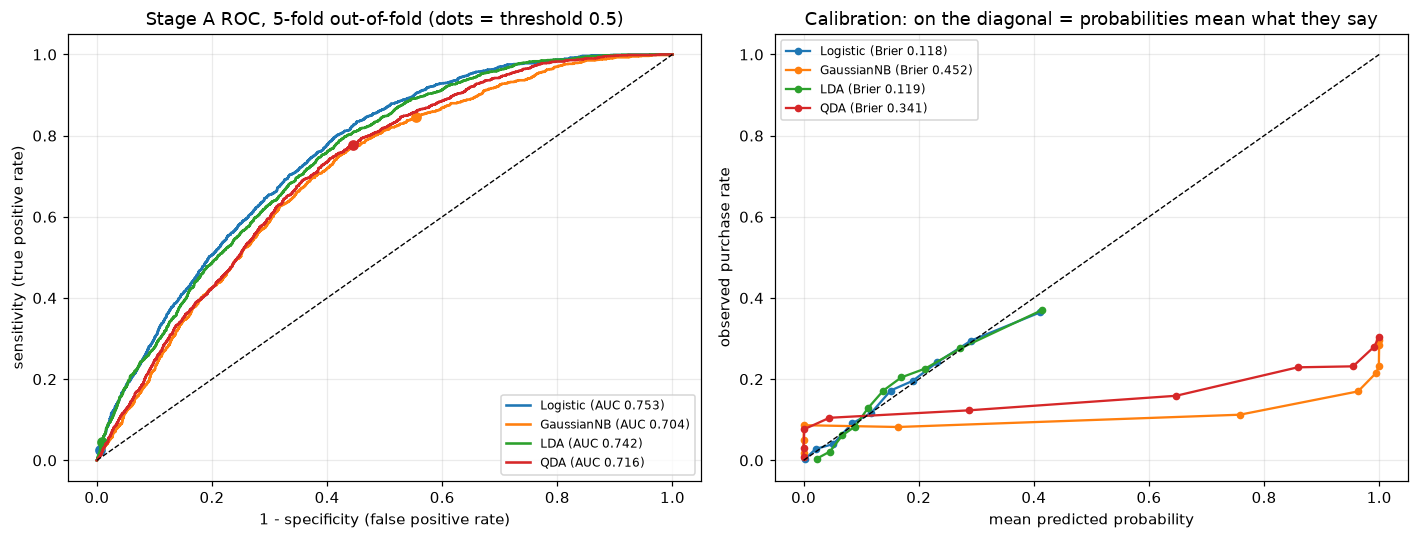

In [19]:
QREF = ("A", "raw, reg_param=0.01", "QDA")
A_KEYS = {m: ("A", "raw", m) for m in ["Logistic", "GaussianNB", "LDA"]} | {"QDA": QREF}
OOF_A = {m: oof(pipe_of(k)) for m, k in A_KEYS.items()}
rows = []
for m, p in OOF_A.items():
    r = rates(ytr, p, 0.5)
    rows.append({"model": m, "CV AUC (25-fold)": SCORES[A_KEYS[m]].mean(), "SD": SCORES[A_KEYS[m]].std(ddof=1),
                 **r, "predicted-positive rate": (p >= .5).mean(), "Brier": brier_score_loss(ytr, p)})
BASELINE = pd.DataFrame(rows).set_index("model"); display(BASELINE)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for m, p in OOF_A.items():
    fpr, tpr, _ = roc_curve(ytr, p)
    ax[0].plot(fpr, tpr, lw=1.7, label=f"{m} (AUC {roc_auc_score(ytr, p):.3f})")
    r = rates(ytr, p, .5); ax[0].plot(1 - r["spec"], r["sens"], "o", ms=6, color=ax[0].lines[-1].get_color())
ax[0].plot([0, 1], [0, 1], "k--", lw=.9)
ax[0].set_xlabel("1 - specificity (false positive rate)"); ax[0].set_ylabel("sensitivity (true positive rate)")
ax[0].set_title("Stage A ROC, 5-fold out-of-fold (dots = threshold 0.5)"); ax[0].legend(fontsize=8, loc="lower right")
for m, p in OOF_A.items():
    fp_, mp_ = calibration_curve(ytr, p, n_bins=10, strategy="quantile")
    ax[1].plot(mp_, fp_, "o-", ms=4, label=f"{m} (Brier {brier_score_loss(ytr, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=.9)
ax[1].set_xlabel("mean predicted probability"); ax[1].set_ylabel("observed purchase rate")
ax[1].set_title("Calibration: on the diagonal = probabilities mean what they say"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What it tells us.** Logistic ranks best (AUC 0.752), then LDA (0.741), QDA (0.715) and NB (0.704): the order the assumption tests predicted. At 0.5, Logistic catches only 2.5% of buyers, while NB catches 85%, yet NB is the worst ranker. The calibration plot resolves this: NB's probabilities are pushed to the extremes (Brier 0.452 vs 0.118), so its 0.5 point sits somewhere else on its curve. High sensitivity at 0.5 is an artefact of miscalibration, not skill.
**Real-world meaning.** At 0.5, the best model would route support to fewer than 1 session in 100 and miss 97% of buyers.

### Why is sensitivity so low at 0.5?
**Purpose.** Explain the problem the rest of the project attacks. **Method.** The distribution of
predicted probabilities for buyers and non-buyers.

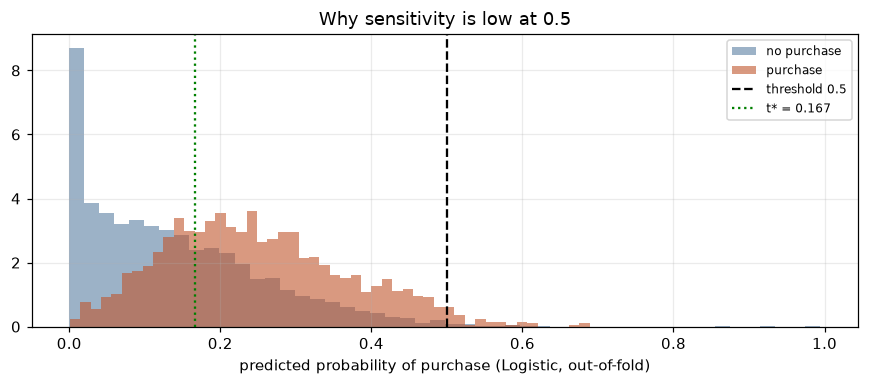

buyers with predicted p >= 0.5 : 2.5%
buyers with predicted p >= t*  : 71.6%
median predicted p for buyers  : 0.235   (base rate 0.155)


In [20]:
p = OOF_A["Logistic"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(p[ytr == 0], bins=50, alpha=.6, density=True, label="no purchase", color="#5b7fa3")
ax.hist(p[ytr == 1], bins=50, alpha=.6, density=True, label="purchase", color="#c0562c")
ax.axvline(.5, color="k", ls="--", label="threshold 0.5"); ax.axvline(T_STAR, color="g", ls=":", label=f"t* = {T_STAR:.3f}")
ax.set_xlabel("predicted probability of purchase (Logistic, out-of-fold)"); ax.legend(fontsize=8)
ax.set_title("Why sensitivity is low at 0.5"); plt.tight_layout(); plt.show()
print(f"buyers with predicted p >= 0.5 : {(p[ytr == 1] >= .5).mean():.1%}")
print(f"buyers with predicted p >= t*  : {(p[ytr == 1] >= T_STAR).mean():.1%}")
print(f"median predicted p for buyers  : {np.median(p[ytr == 1]):.3f}   (base rate {rate:.3f})")

**What it tells us.** Only 2.5% of buyers score above 0.5; the median buyer scores 0.235. With a 15.5% base rate, a well-calibrated model is rarely more than 50% sure of anyone. Moving to t* = 0.167 catches 71.6% of buyers. Stage E separates the two causes.

## §6 Stage B — Transformations

**Purpose.** §4 showed every numeric feature is heavily skewed, which breaks the normality assumed by NB,
LDA and QDA and the linearity assumed by logistic regression. A transformation reshapes a feature toward
a bell curve. **Method.** Four candidates, each fitted inside the fold:
- **log1p** — log(1+x): simple, handles zeros;
- **Yeo–Johnson** — a fitted power transform that picks the best curvature per feature;
- **quantile** — maps each feature's ranks onto a normal distribution;
- **zero-indicator** — log1p plus a 0/1 "any activity" flag for features that are zero ≥ 20% of the
  time, because no transformation can turn a spike at zero into a bell curve.

First, did they fix the shape? Standardisation (scaling) is *not* one of these: it is linear and
leaves shape unchanged, so the baseline already includes it.

In [21]:
TRANSFORMS = ["log1p", "yeojohnson", "quantile", "zeroind"]
def transformed(t, X):
    s = tf_step(t, NUMM)
    A = X[NUMM].values if s == "passthrough" else clone(s).fit(Xtr[NUMM]).transform(X[NUMM])
    return pd.DataFrame(np.asarray(A)[:, :len(NUMM)], columns=NUMM)
rows = []
for t in ["none"] + TRANSFORMS:
    T = transformed(t, Xtr)
    sk = T.apply(stats.skew)
    Gt = [T[ytr.values == k].values for k in (0, 1)]
    rows.append({"transform": t, "mean |skew|": sk.abs().mean(), "features |skew|>1": int((sk.abs() > 1).sum()),
                 "median K2 (lower = more normal)": np.median([stats.normaltest(T[c])[0] for c in NUMM]),
                 "Box's M chi2": box_m(Gt)[1]})
TDIAG = pd.DataFrame(rows).set_index("transform"); display(TDIAG)
SKEW_BY_T = pd.DataFrame({t: transformed(t, Xtr).apply(stats.skew) for t in ["none"] + TRANSFORMS})
display(SKEW_BY_T.round(2))
print(f"zero-heavy features (>= 20% zeros, decided on training data): {ZERO_HEAVY}")

,mean |skew|,features |skew|>1,median K2 (lower = more normal),Box's M chi2
transform,,,,
none,4.6732,8,8438.8312,4651.5117
log1p,1.3923,5,3284.0192,4181.1986
yeojohnson,0.6068,3,1482.9123,1444.9913
quantile,0.8558,4,3111.7399,2106.2951
zeroind,1.3923,5,3284.0192,4181.1986


,none,log1p,yeojohnson,quantile,zeroind
Administrative,1.99,0.57,0.24,-0.06,0.57
Administrative_Duration,5.72,0.25,0.14,-0.02,0.25
Informational,4.19,2.03,1.40,1.42,2.03
Informational_Duration,7.80,1.92,1.55,1.57,1.92
ProductRelated,4.40,-0.05,-0.00,-0.22,-0.05
ProductRelated_Duration,8.23,-1.42,-0.04,-1.83,-1.42
BounceRates,2.93,2.86,1.04,0.22,2.86
ExitRates,2.13,2.04,0.44,1.50,2.04


zero-heavy features (>= 20% zeros, decided on training data): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'BounceRates', 'time_per_admin_page']


**What it tells us.** Yeo–Johnson reshapes best: mean |skew| falls from 4.67 to 0.61, and Box's M falls from 4,652 to 1,445. log1p barely touches the rates (`BounceRates` 2.93 → 2.86), because log(1+x) ≈ x when x is tiny. The informational features stay skewed under every transform, because a spike at zero cannot become a bell curve; that is why the zero-indicator variant exists. (Its shape row equals log1p's because the indicators are separate 0/1 columns.)

**Did reshaping improve prediction?** Each transformation applied to each method, compared fold by fold
with that method's own baseline.

CV AUC   Δ AUC           p         verdict
model      variant                                               
Logistic   log1p       0.7595  0.0079  3.6697e-04            GAIN
           yeojohnson  0.7604  0.0087  3.0731e-04            GAIN
           quantile    0.7590  0.0073  1.2316e-02            GAIN
           zeroind     0.7618  0.0101  1.4428e-04            GAIN
GaussianNB log1p       0.7103  0.0060  5.2700e-03            GAIN
           yeojohnson  0.7074  0.0031  1.6304e-01  no sig. change
           quantile    0.6945 -0.0098  8.0560e-04            LOSS
           zeroind     0.7107  0.0064  5.4237e-02  no sig. change
LDA        log1p       0.7439  0.0031  1.3320e-01  no sig. change
           yeojohnson  0.7537  0.0129  1.0321e-05            GAIN
           quantile    0.7432  0.0025  4.1423e-01  no sig. change
           zeroind     0.7518  0.0110  2.6345e-03            GAIN
QDA        log1p       0.7246  0.0099  1.9214e-07            GAIN
           yeojohnson  0.7220  0.0073  8.3583e-03            GAIN
           quantile    0.7084 -0.0063  4.2845e-02            LOSS
           zeroind     0.7253  0.0106  2.0961e-04            GAIN

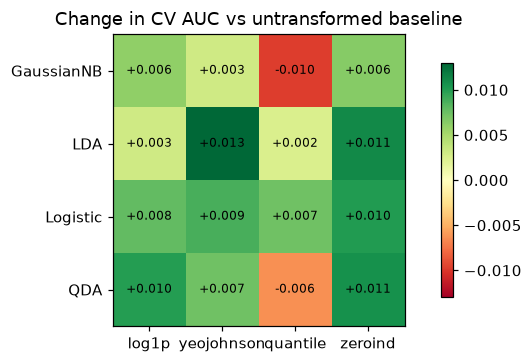

Logistic    carried forward: B:zeroind                AUC 0.7618
GaussianNB  carried forward: B:log1p                  AUC 0.7103
LDA         carried forward: B:yeojohnson             AUC 0.7537
QDA         carried forward: B:zeroind                AUC 0.7253


In [22]:
for m in ["Logistic", "GaussianNB", "LDA", "QDA"]:
    clf = CONF[A_KEYS[m]]["clf"]
    for t in TRANSFORMS:
        record("B", t, m, clf, dict(transform=t), ref=A_KEYS[m])
B = pd.DataFrame(LEDGER).query("stage == 'B'")
grid = B.pivot(index="model", columns="variant", values="Δ AUC")[TRANSFORMS]
display(pd.DataFrame(LEDGER).query("stage == 'B'").set_index(["model", "variant"])[["CV AUC", "Δ AUC", "p", "verdict"]])
fig, ax = plt.subplots(figsize=(7, 3.4))
im = ax.imshow(grid.values, cmap="RdYlGn", vmin=-abs(grid.values).max(), vmax=abs(grid.values).max())
ax.set_xticks(range(len(TRANSFORMS))); ax.set_xticklabels(TRANSFORMS)
ax.set_yticks(range(len(grid))); ax.set_yticklabels(grid.index); ax.grid(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax.text(j, i, f"{grid.values[i, j]:+.3f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=.8); ax.set_title("Change in CV AUC vs untransformed baseline")
plt.tight_layout(); plt.show()
BEST_B = {m: carried(m, "B", A_KEYS[m]) for m in ["Logistic", "GaussianNB", "LDA", "QDA"]}
for m, k in BEST_B.items():
    print(f"{m:<11} carried forward: {k[0]}:{k[1]:<22} AUC {SCORES[k].mean():.4f}")

**What it tells us.** Of 16 method × transform combinations, 10 are significant gains, 4 show no significant change and 2 are losses (quantile, for NB and QDA). Carried forward: Logistic → zero-indicator (+0.010), LDA → Yeo–Johnson (+0.013), QDA → zero-indicator (+0.011), NB → log1p (+0.006).
**A prediction that failed.** We expected NB to gain most; it gained least. Transformation fixes each feature's shape, but NB's larger violation is within-class correlation (§4.3), which reshaping cannot remove.

**Purpose.** Show visually whether the transformation straightened the log-odds (§4.5).

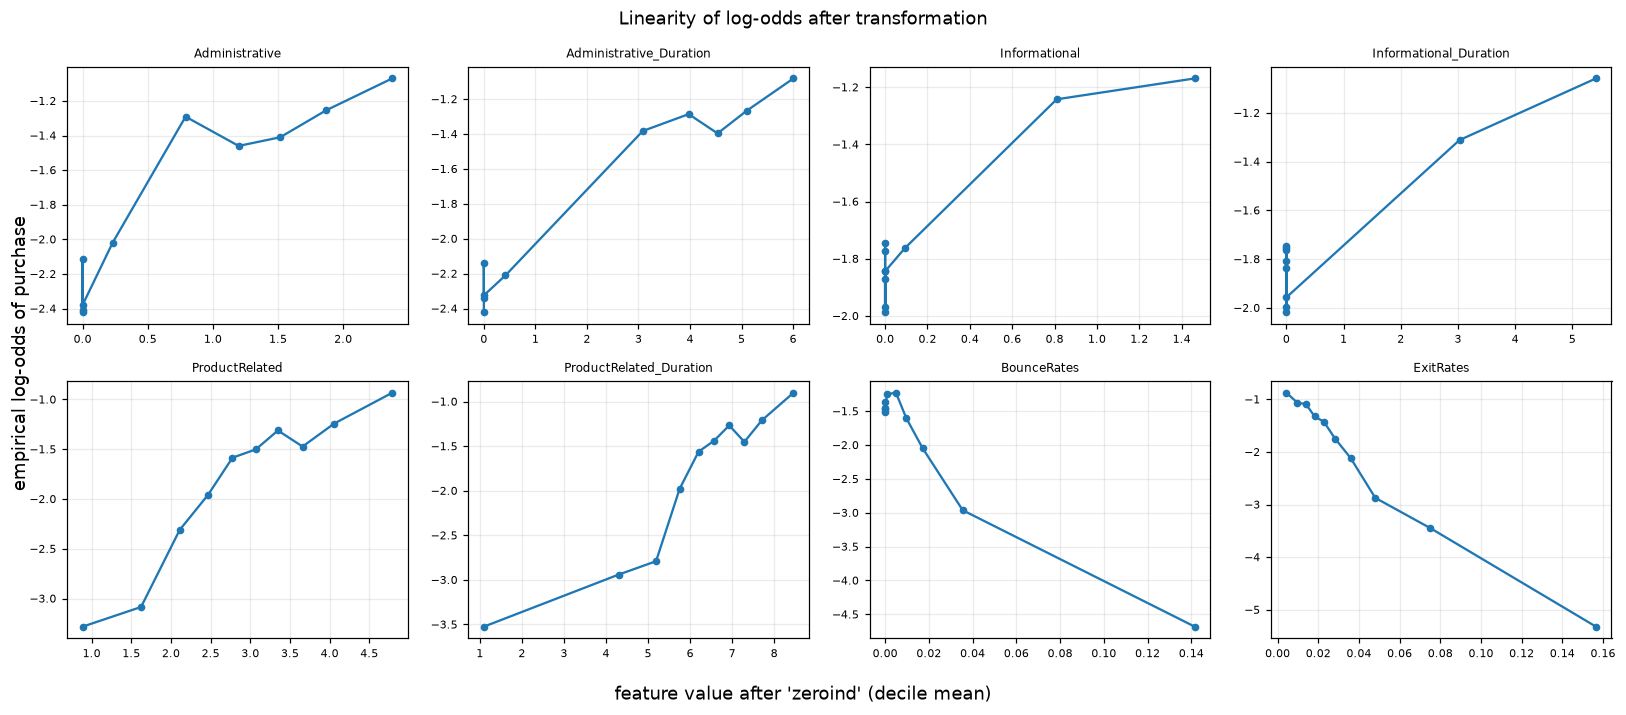

In [23]:
tbest = CONF[BEST_B["Logistic"]]["pre"]["transform"]
T = transformed(tbest if tbest != "none" else "log1p", Xtr)
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.ravel(), NUMM):
    emp_logit_plot(ax, T[c], ytr, c)
fig.supxlabel(f"feature value after '{tbest}' (decile mean)"); fig.supylabel("empirical log-odds of purchase")
plt.suptitle("Linearity of log-odds after transformation"); plt.tight_layout(); plt.show()

**What it tells us.** The count and duration features now climb steadily instead of bending sharply, consistent with Box–Tidwell's weaker rejections (§4.5). Two patterns remain:
- Each zero-heavy feature shows a vertical stack of points at 0. That is the block of zeros split across deciles, and it means going from *no* activity to *some* is a **step**, not a slope. The "any activity" flag models exactly that step, which is why the zero-indicator variant won for Logistic.
- `BounceRates` is effectively untransformed (log(1+x) ≈ x at these tiny values). It still bends: flat near zero, then a steep fall. `ExitRates` is close to linear.

## §7 Stage C — Nonlinearity: polynomials, interactions, and QDA vs LDA

**Purpose.** LDA's shared-covariance assumption forces a straight-line boundary. QDA's class-specific
covariance gives a curved boundary, which mathematically contains every squared term and every pairwise
interaction. So "do polynomial and interaction terms help?" and "does QDA beat LDA?" are **the same
question asked two ways**. We ask it both ways. **Method.** On each method's carried-forward configuration:
polynomial degree 2 and 3, interactions only, five domain features (time per product page, time per
admin page, total pages, total time, share of product pages), and a VisitorType × Month interaction.

In [24]:
for m in ["Logistic", "LDA"]:
    k0 = BEST_B[m]; clf, pre = CONF[k0]["clf"], CONF[k0]["pre"]
    for v, extra, note in [
        ("poly2", dict(poly=2), "all squares + pairwise interactions of numeric features"),
        ("poly2 interactions only", dict(poly=2, inter_only=True), "pairwise interactions, no squares"),
        ("poly3", dict(poly=3), "cubic terms"),
        ("domain features", dict(domain=True), "time/page, total pages, total time, product share"),
        ("domain + poly2", dict(domain=True, poly=2), ""),
        ("VisitorType x Month", dict(cross=True), "categorical interaction")]:
        record("C", v, m, clf, {**pre, **extra}, ref=k0, note=note)
for m in ["GaussianNB", "QDA"]:
    k0 = BEST_B[m]; clf, pre = CONF[k0]["clf"], CONF[k0]["pre"]
    record("C", "domain features", m, clf, {**pre, "domain": True}, ref=k0)
k0 = BEST_B["GaussianNB"]
record("C", "poly2", "GaussianNB", CONF[k0]["clf"], {**CONF[k0]["pre"], "poly": 2}, ref=k0,
       note="expected to hurt: squares are correlated with their own base feature")
display(pd.DataFrame(LEDGER).query("stage == 'C'").set_index(["model", "variant"])[["CV AUC", "Δ AUC", "p", "verdict", "note"]])
BEST_C = {m: carried(m, "C", BEST_B[m]) for m in ["Logistic", "GaussianNB", "LDA", "QDA"]}
kq, kl = BEST_C["QDA"], BEST_C["LDA"]
d, p = corrected_ttest(SCORES[kq], SCORES[kl])
print(f"\nQDA (curved boundary) vs LDA (straight boundary), best of each: Δ AUC {d:+.4f}, p = {p:.3g}")
for m, k in BEST_C.items():
    print(f"{m:<11} carried forward: {k[0]}:{k[1]:<24} AUC {SCORES[k].mean():.4f}")

CV AUC       Δ AUC       p         verdict                                               note
model      variant                                                                                                               
Logistic   poly2                    0.7649  3.1413e-03  0.2918  no sig. change  all squares + pairwise interactions of numeric...
           poly2 interactions only  0.7645  2.7790e-03  0.3126  no sig. change                  pairwise interactions, no squares
           poly3                    0.7610 -7.3102e-04  0.8328  no sig. change                                        cubic terms
           domain features          0.7624  6.0938e-04  0.1067  no sig. change  time/page, total pages, total time, product share
           domain + poly2           0.7666  4.7946e-03  0.1344  no sig. change                                                   
           VisitorType x Month      0.7625  7.8586e-04  0.5140  no sig. change                            categorical interaction
LDA        poly2                    0.7618  8.1116e-03  0.0014            GAIN  all squares + pairwise interactions of numeric...
           poly2 interactions only  0.7612  7.5536e-03  0.0029            GAIN                  pairwise interactions, no squares
           poly3                    0.7557  1.9754e-03  0.6145  no sig. change                                        cubic terms
           domain features          0.7563  2.6682e-03  0.0642  no sig. change  time/page, total pages, total time, product share
           domain + poly2           0.7597  6.0198e-03  0.1119  no sig. change                                                   
           VisitorType x Month      0.7537  4.4151e-05  0.9802  no sig. change                            categorical interaction
GaussianNB domain features          0.7181  7.7538e-03  0.0004            GAIN                                                   
QDA        domain features          0.7280  2.7433e-03  0.0137            GAIN                                                   
GaussianNB poly2                    0.7222  1.1873e-02  0.0331            GAIN  expected to hurt: squares are correlated with ...


QDA (curved boundary) vs LDA (straight boundary), best of each: Δ AUC -0.0337, p = 3.23e-05
Logistic    carried forward: B:zeroind                  AUC 0.7618
GaussianNB  carried forward: C:poly2                    AUC 0.7222
LDA         carried forward: C:poly2                    AUC 0.7618
QDA         carried forward: C:domain features          AUC 0.7280


**What it tells us.** Asked both ways, the curvature question gets a consistent answer.
- **Polynomial and interaction terms help LDA** (+0.008, p = 0.001; interactions alone +0.008) but **not Logistic** (+0.003, p = 0.29). Squared terms let LDA's straight boundary bend. Logistic already bends where it matters through the zero indicators. Cubic terms help neither.
- **QDA does worse than LDA** (−0.034, p < 0.001), even though equal covariance fails (§4.2). QDA estimates a separate covariance matrix over ~70 columns for each class from only 1,431 buyers, and that estimate is noisy. A curved boundary from a few chosen terms (LDA + poly2) beats one built from a whole second covariance matrix. The assumption fails, but relaxing it wholesale costs more variance than it removes in bias.
- Domain features help NB and QDA a little and are not significant for Logistic or LDA. The VisitorType × Month interaction adds nothing (p = 0.51 and 0.98).
- **A second failed prediction.** We expected squared terms to hurt NB, because each square is correlated with its own base feature. They helped (+0.012, p = 0.03). A plausible reason: the extra terms let NB's per-feature Gaussians describe the skewed tails better.

Carried forward: LDA → poly2 · NB → poly2 · QDA → domain features · Logistic stays at its Stage B configuration.

## §8 Stage D — Regularisation (λ) and subset selection

### 8.1 Choosing λ for logistic regression
**Purpose.** Default settings are a choice, not a neutral starting point. The penalty λ trades fit
against stability. **Method.** A validation curve over C = 1/λ for ridge (L2, shrinks coefficients)
and lasso (L1, can set coefficients to zero).

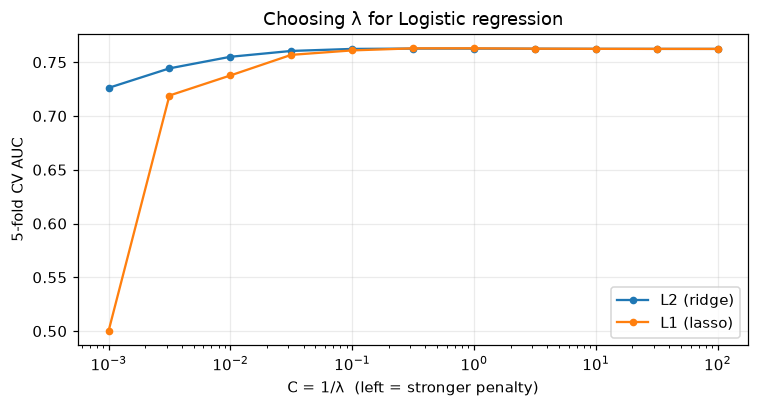

L2 (ridge): best C = 0.3162 (λ = 3.162), CV AUC 0.7627
L1 (lasso): best C = 1 (λ = 1), CV AUC 0.7629


In [25]:
kL = BEST_C["Logistic"]; preL = CONF[kL]["pre"]
Cs = np.logspace(-3, 2, 11)
curve = {}
for name, l1 in [("L2 (ridge)", 0.0), ("L1 (lasso)", 1.0)]:
    curve[name] = [cv5(build(LogisticRegression(C=c, l1_ratio=l1, solver="liblinear", max_iter=5000), **preL)).mean()
                   for c in Cs]
fig, ax = plt.subplots(figsize=(7, 3.8))
for name, v in curve.items():
    ax.semilogx(Cs, v, "o-", ms=4, label=name)
ax.set_xlabel("C = 1/λ  (left = stronger penalty)"); ax.set_ylabel("5-fold CV AUC")
ax.set_title("Choosing λ for Logistic regression"); ax.legend(); plt.tight_layout(); plt.show()
BEST_LAM = {n: (Cs[int(np.argmax(v))], max(v)) for n, v in curve.items()}
for n, (c, a) in BEST_LAM.items():
    print(f"{n}: best C = {c:.4g} (λ = {1/c:.4g}), CV AUC {a:.4f}")
for n, l1 in [("L2 (ridge)", 0.0), ("L1 (lasso)", 1.0)]:
    record("D", f"{n.split()[0]} tuned, C={BEST_LAM[n][0]:.3g}", "Logistic",
           LogisticRegression(C=BEST_LAM[n][0], l1_ratio=l1, solver="liblinear", max_iter=5000), preL, ref=kL)

**What it tells us.** The curve is flat for C ≥ 0.1. The best settings are L2 at C = 0.32 and L1 at C = 1, and on 25 folds neither beats the default significantly (L2 +0.0002, p = 0.74; L1 +0.0005, p = 0.21). Only heavy penalties hurt, and L1 collapses to AUC 0.50 at C = 0.001 because it zeroes every coefficient. The default penalty was already adequate, so the configuration is unchanged. The test still earned its place: the result does not rest on a lucky default.

### 8.2 Subset size
**Purpose.** Would a smaller model do as well? Fewer variables are easier to explain and to deploy.
**Method.** Two routes: the L1 path (how many variables survive at each λ) and forward stepwise
selection over the 16 original variables. The subset size is chosen by the **one-standard-error rule**:
the smallest model within one SE of the best, and never fewer than 5 variables.

,C,variables kept,CV AUC
0,0.0032,5,0.7190
1,0.0056,6,0.7271
2,0.0100,9,0.7376
3,0.0178,12,0.7503
4,0.0316,12,0.7568
5,0.0562,11,0.7598
6,0.1000,14,0.7609
7,0.1778,16,0.7619
8,0.3162,16,0.7629
9,0.5623,16,0.7631


,added,CV AUC,SE
k,,,
1,ExitRates,0.7139,0.0116
2,Month,0.7400,0.0111
3,ProductRelated_Duration,0.7480,0.0102
4,TrafficType,0.7539,0.0108
5,SpecialDay,0.7577,0.0106
6,BounceRates,0.7606,0.0110
7,OperatingSystems,0.7616,0.0104
8,Informational,0.7625,0.0107
9,VisitorType,0.7630,0.0108


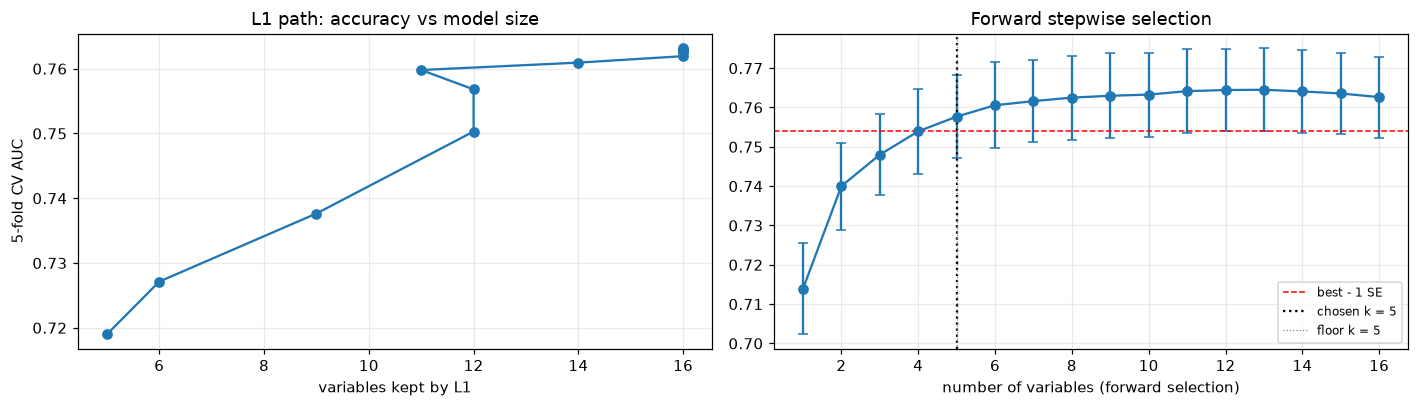

1-SE rule picks k = 5: ['ExitRates', 'Month', 'ProductRelated_Duration', 'TrafficType', 'SpecialDay']


In [26]:
preM = dict(transform=CONF[BEST_B["Logistic"]]["pre"]["transform"])       # main effects: variables map 1:1
ALLV = NUMM + CAT
def var_of(term):
    """Map an encoded column name back to the original variable it came from."""
    s = term.split("__", 1)[1]
    for w in ("log1p(", "any("):
        if s.startswith(w): s = s[len(w):-1]
    return s if s in ALLV else next((v for v in CAT if s.startswith(v + "_")), s)
path = []
for c in np.logspace(-2.5, 0.5, 13):
    clf = LogisticRegression(C=c, l1_ratio=1.0, solver="liblinear", max_iter=5000)
    fit = build(clone(clf), **preM).fit(Xtr, ytr)
    names = fit.named_steps["ct"].get_feature_names_out()
    nz = names[np.abs(fit.named_steps["clf"].coef_[0]) > 1e-8]
    used = {var_of(n) for n in nz}
    path.append({"C": c, "variables kept": len(used), "CV AUC": cv5(build(clone(clf), **preM)).mean()})
L1PATH = pd.DataFrame(path); display(L1PATH.round(4))

sel, remaining, fwd = [], list(ALLV), []
while remaining:
    sc = {}
    for v in remaining:
        n_, c_ = split_view(sel + [v])
        s = cv5(build(LogisticRegression(max_iter=5000), **preM, num=n_, cat=c_))
        sc[v] = (s.mean(), s.std(ddof=1) / np.sqrt(len(s)))
    v = max(sc, key=lambda k: sc[k][0]); sel.append(v); remaining.remove(v)
    fwd.append({"k": len(sel), "added": v, "CV AUC": sc[v][0], "SE": sc[v][1]})
FWD = pd.DataFrame(fwd).set_index("k"); display(FWD.round(4))
best_row = FWD["CV AUC"].idxmax()
thr = FWD.loc[best_row, "CV AUC"] - FWD.loc[best_row, "SE"]
K_SEL = int(max(5, FWD.index[FWD["CV AUC"] >= thr].min()))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(L1PATH["variables kept"], L1PATH["CV AUC"], "o-"); ax[0].set_xlabel("variables kept by L1")
ax[0].set_ylabel("5-fold CV AUC"); ax[0].set_title("L1 path: accuracy vs model size")
ax[1].errorbar(FWD.index, FWD["CV AUC"], yerr=FWD["SE"], fmt="o-", capsize=3)
ax[1].axhline(thr, color="r", ls="--", lw=1, label="best - 1 SE"); ax[1].axvline(K_SEL, color="k", ls=":", label=f"chosen k = {K_SEL}")
ax[1].axvline(5, color="grey", ls=":", lw=.8, label="floor k = 5")
ax[1].set_xlabel("number of variables (forward selection)"); ax[1].set_title("Forward stepwise selection")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()
SUBSET = list(FWD["added"].iloc[:K_SEL])
print(f"1-SE rule picks k = {K_SEL}: {SUBSET}")
n_, c_ = split_view(SUBSET)
_ = record("D", f"forward-selected {K_SEL} variables", "Logistic", LogisticRegression(max_iter=5000),
       {**preM, "num": n_, "cat": c_}, ref=BEST_C["Logistic"], note="1-SE rule, floor of 5 variables")

**What it tells us.** Both routes agree: accuracy climbs fast for the first few variables, then plateaus. Forward selection adds `ExitRates`, `Month`, `ProductRelated_Duration`, `TrafficType` and `SpecialDay` first. Beyond about 8 variables each addition changes AUC by less than 0.002, and `Region`, added last, lowers it slightly (§2.4 found it unrelated to purchase). The one-standard-error rule picks **k = 5**, which also meets the floor of five. On 25 folds that 5-variable model scores 0.758, against 0.762 for all 16 (−0.004, p = 0.15): not significantly worse.

**A judgement call.** Our parsimony rule adopts only significant *gains*, so the full model is carried forward. Where explaining the model matters more than the last 0.004 AUC, the 5-variable model is the defensible choice.

**Real-world meaning.** Five things carry most of the signal: how visitors exit, time on product pages, the month, the traffic source, and closeness to a holiday.

### 8.3 Tuning the other three methods
**Purpose.** Give every method its best shot. **Method.** LDA shrinkage (pulls the covariance estimate
toward a simpler form), QDA's reg_param (the same idea per class), and Naive Bayes' var_smoothing
(adds a small variance floor).

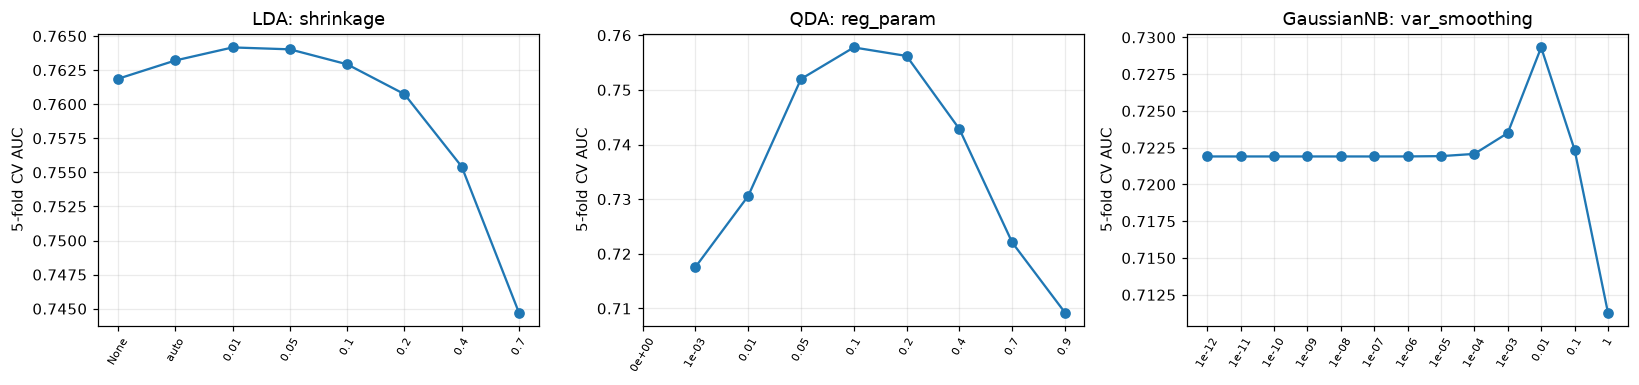

CV AUC   Δ AUC           p         verdict                             note
model      variant                                                                                                  
Logistic   L2 tuned, C=0.316             0.7619  0.0002  7.4492e-01  no sig. change                                 
           L1 tuned, C=1                 0.7622  0.0005  2.0523e-01  no sig. change                                 
           forward-selected 5 variables  0.7579 -0.0039  1.5279e-01  no sig. change  1-SE rule, floor of 5 variables
LDA        shrinkage tuned = 0.01        0.7635  0.0017  1.3679e-01  no sig. change                                 
QDA        reg_param tuned = 0.1         0.7565  0.0284  2.8432e-05            GAIN                                 
GaussianNB var_smoothing tuned = 0.01    0.7292  0.0070  3.2225e-03            GAIN

In [27]:
tune = {
 "LDA": ("shrinkage", [None, "auto", 0.01, 0.05, 0.1, 0.2, 0.4, 0.7],
         lambda v: LDA(solver="lsqr", shrinkage=v)),
 "QDA": ("reg_param", [0.0, 1e-3, 0.01, 0.05, 0.1, 0.2, 0.4, 0.7, 0.9],
         lambda v: QDA(reg_param=v)),
 "GaussianNB": ("var_smoothing", list(np.logspace(-12, 0, 13)),
                lambda v: GaussianNB(var_smoothing=v))}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (m, (pname, grid_, mk)) in zip(axes, tune.items()):
    k0 = BEST_C[m]; pre = CONF[k0]["pre"]
    sc = [cv5(build(mk(v), **pre)).mean() for v in grid_]
    ax.plot(range(len(grid_)), sc, "o-"); ax.set_xticks(range(len(grid_)))
    ax.set_xticklabels([str(v) if not isinstance(v, float) else f"{v:.0e}" if v < 1e-2 else f"{v:g}" for v in grid_],
                       rotation=60, fontsize=7)
    ax.set_title(f"{m}: {pname}"); ax.set_ylabel("5-fold CV AUC")
    bv = grid_[int(np.nanargmax(sc))]
    record("D", f"{pname} tuned = {bv}", m, mk(bv), pre, ref=k0)
plt.tight_layout(); plt.show()
display(pd.DataFrame(LEDGER).query("stage == 'D'").set_index(["model", "variant"])[["CV AUC", "Δ AUC", "p", "verdict", "note"]])

**What it tells us.** QDA gains most from tuning: reg_param = 0.1 lifts it from 0.728 to 0.757 (+0.028, p < 0.001). This confirms §7's diagnosis that its covariance estimates needed shrinking. NB gains from var_smoothing = 0.01 (+0.007, p = 0.003). LDA's shrinkage adds nothing significant (+0.002, p = 0.14), so LDA stays unregularised. Every curve falls away at the strongest settings, which shows the cost of over-regularising.

## §9 Stage E — Sensitivity: cause, fix, effect

**Purpose.** §5 found two possible causes of low sensitivity. Each has a different kind of fix, and they
must be told apart:

| Cause | Fix | Expected effect on the ROC curve |
|---|---|---|
| **A.** Threshold 0.5 is mismatched to a 15.5% purchase rate | move the threshold; class weights; resampling | **slide along** the curve: buy sensitivity with specificity; AUC unchanged |
| **B.** Features carry limited signal | better transforms, features, models (Stages B–D) | **lift** the curve: more sensitivity at the *same* specificity; AUC rises |

**Method.** Apply every Cause-A fix to the best logistic model — threshold moving, `class_weight='balanced'`,
random oversampling, random undersampling, and SMOTENC (synthetic buyers for mixed numeric/categorical
data). Resampling runs inside each training fold only; the validation fold is never resampled.

In [28]:
BEST_D = {m: carried(m, "D", BEST_C[m]) for m in ["Logistic", "GaussianNB", "LDA", "QDA"]}
for m, k in BEST_D.items():
    print(f"{m:<11} carried forward: {k[0]}:{k[1]:<30} AUC {SCORES[k].mean():.4f}")
kE = BEST_D["Logistic"]; clfE, preE = CONF[kE]["clf"], CONF[kE]["pre"]
cw = clone(clfE).set_params(class_weight="balanced")
FIXES = {
 "class_weight='balanced'": dict(clf=cw, sampler=None),
 "random oversampling":     dict(clf=clfE, sampler=RandomOverSampler(random_state=SEED)),
 "random undersampling":    dict(clf=clfE, sampler=RandomUnderSampler(random_state=SEED)),
 "SMOTENC":                 dict(clf=clfE, sampler=SMOTENC(categorical_features=CAT, random_state=SEED))}
for v, f in FIXES.items():
    record("E", v, "Logistic", f["clf"], preE, ref=kE, sampler=f["sampler"],
           note="resampling fitted inside each training fold" if f["sampler"] is not None else "")
p_base = oof(pipe_of(kE))
ts_, c_, _, _ = cost_curve(ytr, p_base); t_opt = ts_[c_.argmin()]
pts = {"no fix, t = 0.5": (SCORES[kE], rates(ytr, p_base, .5)),
       f"threshold moved to {t_opt:.3f}": (SCORES[kE], rates(ytr, p_base, t_opt))}
for v in FIXES:
    k_ = ("E", v, "Logistic")
    pts[f"{v}, t = 0.5"] = (SCORES[k_], rates(ytr, oof(pipe_of(k_)), .5))
EFX = pd.DataFrame([{"fix": k, "CV AUC": s_.mean(), "sensitivity": r["sens"], "specificity": r["spec"]}
                    for k, (s_, r) in pts.items()]).set_index("fix")
display(EFX)

Logistic    carried forward: B:zeroind                        AUC 0.7618
GaussianNB  carried forward: D:var_smoothing tuned = 0.01     AUC 0.7292
LDA         carried forward: C:poly2                          AUC 0.7618
QDA         carried forward: D:reg_param tuned = 0.1          AUC 0.7565


,CV AUC,sensitivity,specificity
fix,,,
"no fix, t = 0.5",0.7618,0.0419,0.9909
threshold moved to 0.140,0.7618,0.8022,0.5905
"class_weight='balanced', t = 0.5",0.7604,0.7519,0.6315
"random oversampling, t = 0.5",0.7597,0.7533,0.6314
"random undersampling, t = 0.5",0.7560,0.7428,0.6323
"SMOTENC, t = 0.5",0.6961,0.4437,0.7826


**What it tells us.** Every Cause-A fix leaves AUC roughly where it was, yet moves sensitivity from 0.04 to 0.74–0.80. Threshold moving (sensitivity 0.80, specificity 0.59) and class weights (0.75 / 0.63) end in almost the same place. Two resampling methods *lost* ranking quality: random undersampling −0.006 (p = 0.04), because it discards about 80% of the non-buyers in each fold, and SMOTENC −0.066 (p < 10⁻⁷).

**Evidence for the table above.** Left: all Cause-A fixes plotted on one ROC curve. Right: the baseline
and best models' ROC curves, with sensitivity compared at fixed specificity.

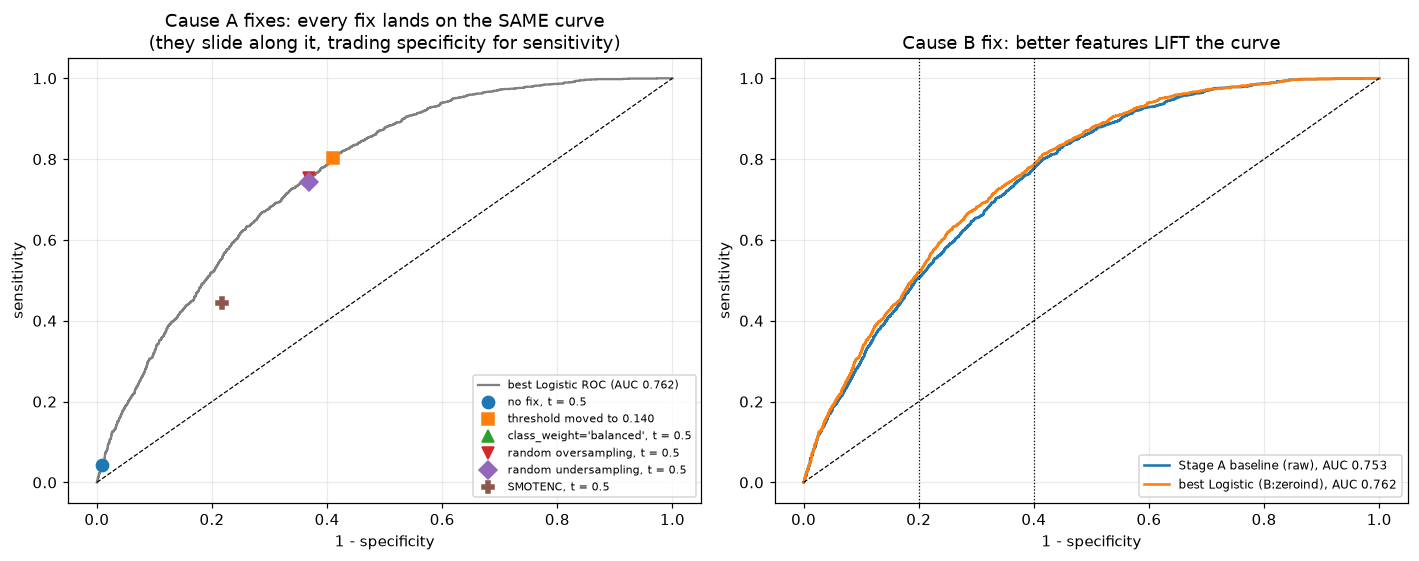

,"sensitivity, baseline","sensitivity, best",gain
at specificity,,,
0.6,0.7771,0.7862,0.0091
0.7,0.6548,0.6778,0.0231
0.8,0.5059,0.5199,0.0140
0.9,0.3005,0.3208,0.0203


In [29]:
p_raw = OOF_A["Logistic"]
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
fpr, tpr, _ = roc_curve(ytr, p_base)
ax[0].plot(fpr, tpr, color="grey", lw=1.5, label=f"best Logistic ROC (AUC {roc_auc_score(ytr, p_base):.3f})")
for (k, (_, r)), mk in zip(pts.items(), ["o", "s", "^", "v", "D", "P"]):
    ax[0].plot(1 - r["spec"], r["sens"], mk, ms=8, label=k)
ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
ax[0].set_xlabel("1 - specificity"); ax[0].set_ylabel("sensitivity")
ax[0].set_title("Cause A fixes: every fix lands on the SAME curve\n(they slide along it, trading specificity for sensitivity)")
ax[0].legend(fontsize=7, loc="lower right")
for p_, lab in [(p_raw, "Stage A baseline (raw)"), (p_base, f"best Logistic ({kE[0]}:{kE[1]})")]:
    f_, t_, _ = roc_curve(ytr, p_); ax[1].plot(f_, t_, lw=1.7, label=f"{lab}, AUC {roc_auc_score(ytr, p_):.3f}")
for s in (0.6, 0.8):
    ax[1].axvline(1 - s, color="k", ls=":", lw=.8)
ax[1].plot([0, 1], [0, 1], "k--", lw=.8)
ax[1].set_xlabel("1 - specificity"); ax[1].set_ylabel("sensitivity")
ax[1].set_title("Cause B fix: better features LIFT the curve"); ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
LIFT = pd.DataFrame([{"at specificity": s, "sensitivity, baseline": sens_at_spec(ytr, p_raw, s),
                      "sensitivity, best": sens_at_spec(ytr, p_base, s)} for s in (0.6, 0.7, 0.8, 0.9)]).set_index("at specificity")
LIFT["gain"] = LIFT["sensitivity, best"] - LIFT["sensitivity, baseline"]
display(LIFT)

**What it tells us.** *Left:* threshold moving, class weights, oversampling and undersampling all land on the **same ROC curve**. Cause-A fixes only pick a different point on one trade-off. SMOTENC lands *below* the curve: it damaged the model rather than moving along it. *Right:* better features lift the curve, but modestly: +0.9 to +2.3 points of sensitivity at a fixed specificity (e.g. 0.655 → 0.678 at specificity 0.7).

| Cause | Fix | Measured effect |
|---|---|---|
| A. threshold mismatched to the 15.5% base rate | move threshold 0.5 → 0.14 | AUC unchanged; sensitivity 0.04 → 0.80, specificity 0.99 → 0.59 |
| A | class weights / oversampling | AUC −0.001 / −0.002 (not significant); same curve |
| A | undersampling / SMOTENC | AUC −0.006 / −0.066 (significant losses) |
| B. features carry limited signal | transformations (Stage B) | AUC 0.752 → 0.762; +0.9 to +2.3 points of sensitivity at fixed specificity |

**Decision.** Use threshold moving. It achieves what rebalancing does, keeps probabilities calibrated, and adds nothing to the pipeline.
**Real-world meaning.** Most of the sensitivity problem is a policy choice (where to set the threshold), not a modelling failure. Better modelling helps only at the margin.

## §10 Ceiling benchmark

**Purpose.** Establish whether the remaining limit is the data or our choice of model. **Method.**
Gradient boosting and a random forest can capture any nonlinearity or interaction without being told to.
They are benchmarks only; the final model stays within the brief's methods.

In [30]:
kL = BEST_D["Logistic"]
record("F", "HistGradientBoosting", "benchmark", HistGradientBoostingClassifier(random_state=SEED),
       BASE, ref=kL, note="flexible: any nonlinearity or interaction")
record("F", "HistGradientBoosting (slow, regularised)", "benchmark",
       HistGradientBoostingClassifier(learning_rate=0.03, max_iter=600, max_leaf_nodes=15,
                                      l2_regularization=1.0, min_samples_leaf=40, random_state=SEED),
       BASE, ref=kL)
record("F", "RandomForest (500 trees)", "benchmark",
       RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=1, random_state=SEED),
       BASE, ref=kL)
display(pd.DataFrame(LEDGER).query("stage == 'F'").set_index("variant")[["CV AUC", "SD", "Δ AUC", "p", "verdict"]])
bm = max([k for k in SCORES if k[0] == "F"], key=lambda k: SCORES[k].mean())
print(f"best benchmark {bm[1]}: {SCORES[bm].mean():.4f} vs best Logistic {SCORES[kL].mean():.4f} "
      f"(gap {SCORES[bm].mean() - SCORES[kL].mean():+.4f})")

,CV AUC,SD,Δ AUC,p,verdict
variant,,,,,
HistGradientBoosting,0.7774,0.0133,0.0156,7.8575e-03,GAIN
"HistGradientBoosting (slow, regularised)",0.7808,0.0132,0.0190,2.9032e-04,GAIN
RandomForest (500 trees),0.7861,0.0133,0.0244,1.8693e-05,GAIN


best benchmark RandomForest (500 trees): 0.7861 vs best Logistic 0.7618 (gap +0.0244)


**What it tells us.** All three flexible benchmarks significantly beat our best logistic model. The random forest reaches 0.786, **+0.024 AUC**. So the data is *not* the only limit: there is nonlinear structure (thresholds, higher-order interactions) that a linear boundary, even with squared terms, does not capture.
**Why the final model still comes from the brief's methods.** The brief requires logistic regression, Naive Bayes and LDA. This benchmark measures what those methods leave on the table: about 0.02–0.025 AUC.
**Real-world meaning.** If those extra points matter commercially, a tree ensemble is the next step, at a cost in interpretability.

## §11 Results ledger — every variant tried

**Purpose.** Show the full working, including what did not help. Each row is scored on the same 25 folds
and compared with the configuration it tried to improve.

CV AUC      SD                     vs       Δ AUC           p         verdict                                               note
stage model      variant                                                                                                                                                                   
A     Logistic   raw                                       0.7517  0.0158                    NaN         NaN         NaN             NaN      baseline: no transformation, default settings
      GaussianNB raw                                       0.7043  0.0151                    NaN         NaN         NaN             NaN      baseline: no transformation, default settings
      LDA        raw                                       0.7407  0.0151                    NaN         NaN         NaN             NaN      baseline: no transformation, default settings
      QDA        raw                                          NaN     NaN                    NaN         NaN         NaN   FAILED TO FIT  baseline: no transformation, default settings ...
                 raw, reg_param=0.01                       0.7147  0.0139                    NaN         NaN         NaN             NaN  minimal ridge so each class covariance is inve...
B     Logistic   log1p                                     0.7595  0.0162                  A:raw  7.8560e-03  3.6697e-04            GAIN                                                   
                 yeojohnson                                0.7604  0.0170                  A:raw  8.7409e-03  3.0731e-04            GAIN                                                   
                 quantile                                  0.7590  0.0175                  A:raw  7.2788e-03  1.2316e-02            GAIN                                                   
                 zeroind                                   0.7618  0.0165                  A:raw  1.0063e-02  1.4428e-04            GAIN                                                   
      GaussianNB log1p                                     0.7103  0.0147                  A:raw  6.0453e-03  5.2700e-03            GAIN                                                   
                 yeojohnson                                0.7074  0.0169                  A:raw  3.0829e-03  1.6304e-01  no sig. change                                                   
                 quantile                                  0.6945  0.0160                  A:raw -9.7615e-03  8.0560e-04            LOSS                                                   
                 zeroind                                   0.7107  0.0137                  A:raw  6.3864e-03  5.4237e-02  no sig. change                                                   
      LDA        log1p                                     0.7439  0.0151                  A:raw  3.1204e-03  1.3320e-01  no sig. change                                                   
                 yeojohnson                                0.7537  0.0160                  A:raw  1.2937e-02  1.0321e-05            GAIN                                                   
                 quantile                                  0.7432  0.0165                  A:raw  2.4926e-03  4.1423e-01  no sig. change                                                   
                 zeroind                                   0.7518  0.0165                  A:raw  1.1024e-02  2.6345e-03            GAIN                                                   
      QDA        log1p                                     0.7246  0.0143  A:raw, reg_param=0.01  9.9417e-03  1.9214e-07            GAIN                                                   
                 yeojohnson                                0.7220  0.0170  A:raw, reg_param=0.01  7.2802e-03  8.3583e-03            GAIN                                                   
                 quantile                                  0.7084  0.0165  A:raw, reg_param=0.01 -6.3084e-03  4

verdict
GAIN              20
no sig. change    20
LOSS               4
FAILED TO FIT      1


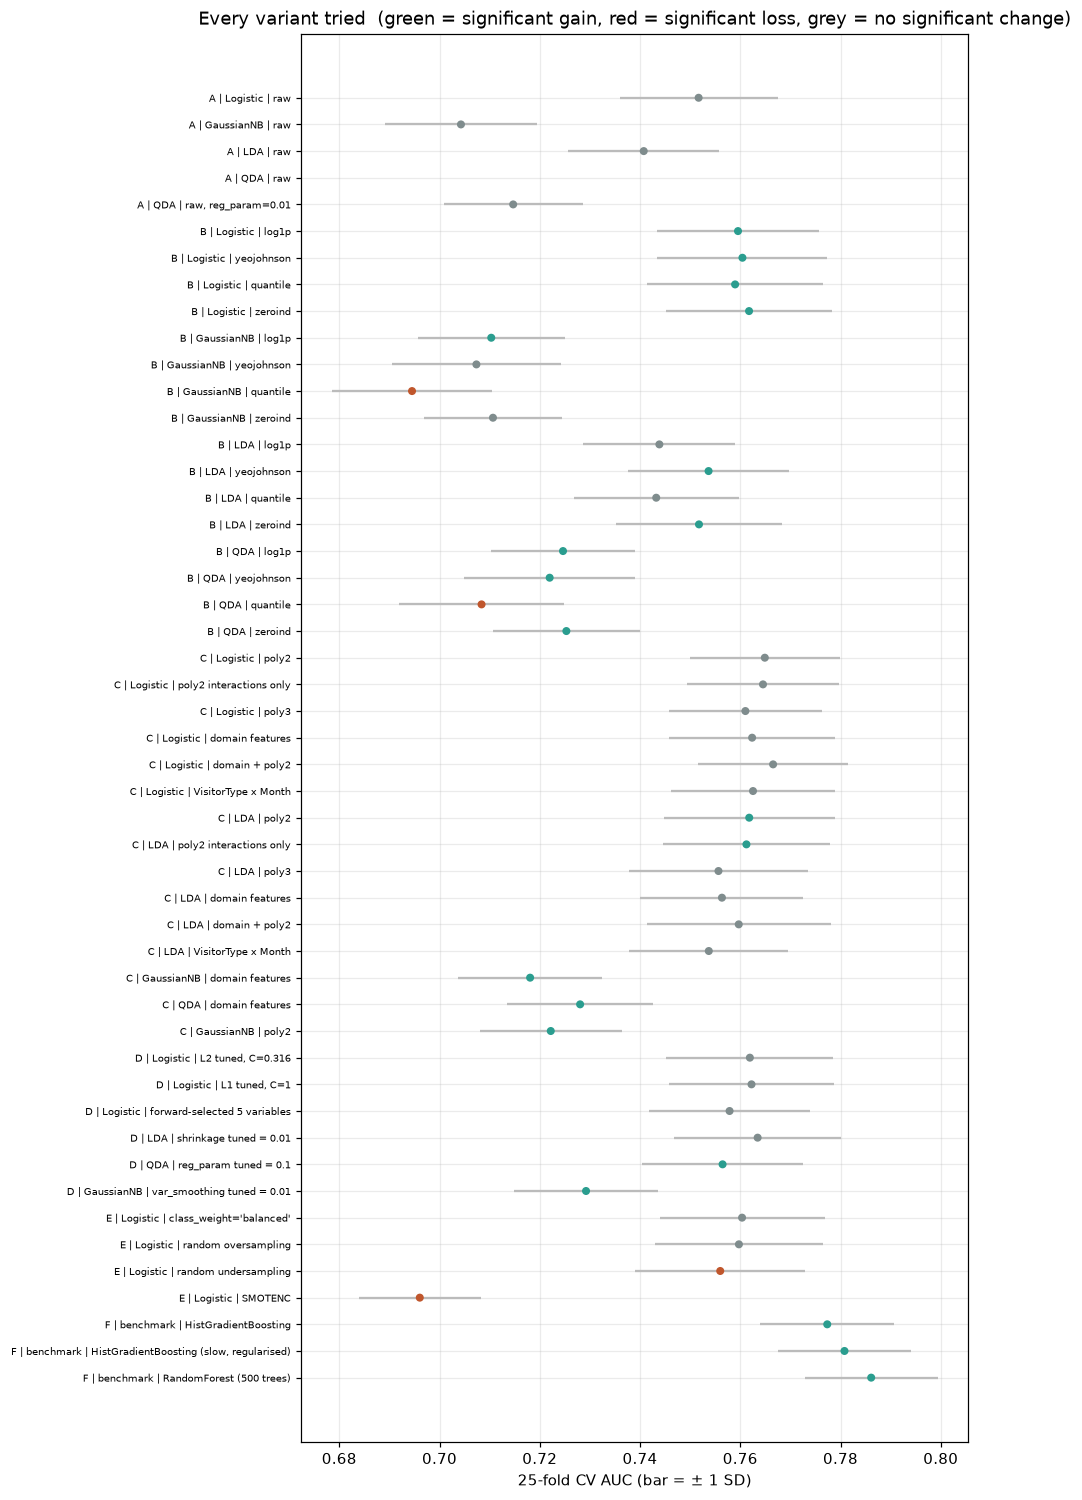

In [31]:
LED = pd.DataFrame(LEDGER)
display(LED.set_index(["stage", "model", "variant"])[["CV AUC", "SD", "vs", "Δ AUC", "p", "verdict", "note"]])
print(LED["verdict"].value_counts(dropna=True).to_string())
fig, ax = plt.subplots(figsize=(9, 0.26 * len(LED) + 1))
lab = LED["stage"] + " | " + LED["model"] + " | " + LED["variant"]
col = LED["verdict"].map({"GAIN": "#2a9d8f", "LOSS": "#c0562c"}).fillna("#7f8c8d")
ax.errorbar(LED["CV AUC"], range(len(LED)), xerr=LED["SD"], fmt="none", ecolor="#bbbbbb")
ax.scatter(LED["CV AUC"], range(len(LED)), c=col, zorder=3, s=18)
ax.set_yticks(range(len(LED))); ax.set_yticklabels(lab, fontsize=6.5); ax.invert_yaxis()
ax.set_xlabel("25-fold CV AUC (bar = ± 1 SD)")
ax.set_title("Every variant tried  (green = significant gain, red = significant loss, grey = no significant change)")
plt.tight_layout(); plt.show()

**What it tells us.** 49 rows: 4 baseline references, 20 significant gains (3 of them the benchmarks), 20 with no significant change, 4 significant losses (quantile for NB and QDA, undersampling, SMOTENC) and 1 failure to fit (default QDA). Roughly half of what we tried did not help, and all of it is kept. The real gains came from Stage B (transformations) and from tuning QDA and NB. Polynomials, domain features and λ changed little for the strongest models.

**Reading the ledger through the bias–variance trade-off.** Most results follow one pattern. Flexible models lower
bias but raise variance, and which effect wins depends on how much data supports each parameter.
- **QDA < LDA** (§7): QDA's separate covariance per class lowers bias but is estimated from only 1,431 buyers, so
  variance wins (Appendix A7 counts the parameters). Tuning reg_param (§8.3) shrinks QDA back toward LDA and
  recovers much of the gap.
- **Polynomial degree 2 helps LDA, but degree 3 helps neither method** (§7): each step up adds variance faster than
  it removes bias.
- **The λ curves** (§8.1): heavy penalties underfit (bias); beyond C ≈ 0.1 the curve is flat, because 9,247
  sessions are plenty for about 70 coefficients, so there is little variance left to remove.
- **The one-standard-error rule** (§8.2) deliberately trades a little bias for a simpler, lower-variance model.
- **The ceiling models** (§10) are low-bias and still win, which shows there is structure the linear boundaries
  cannot represent.

## §12 Choosing the final model

**Purpose.** Pick one model on the two grounds the brief requires. **Method.** Each method's
carried-forward configuration. Ground 1: CV AUC with a corrected significance test. Ground 2: expected
cost per session at each model's own cost-optimal threshold. If the grounds disagree, cost decides,
because it encodes the business objective.

In [32]:
FAM = ["Logistic", "GaussianNB", "LDA", "QDA"]
CAND = dict(BEST_D)
rows = []
for m, k in CAND.items():
    p_ = oof(pipe_of(k)); ts, c_, _, _ = cost_curve(ytr, p_)
    rows.append({"model": m, "best configuration": f"{k[0]}:{k[1]}", "CV AUC": SCORES[k].mean(), "SD": SCORES[k].std(ddof=1),
                 "own cost-optimal t": ts[c_.argmin()], "expected cost / session": c_.min()})
FINALS = pd.DataFrame(rows).set_index("model").sort_values("CV AUC", ascending=False); display(FINALS)
w_auc, r_up = FINALS.index[0], FINALS.index[1]
d, p = corrected_ttest(SCORES[CAND[w_auc]], SCORES[CAND[r_up]])
w_cost = FINALS["expected cost / session"].idxmin()
print(f"Ground 1, performance : {w_auc} (vs {r_up}: Δ AUC {d:+.4f}, corrected p = {p:.3g})")
print(f"Ground 2, cost        : {w_cost}")
FINAL = w_auc if w_auc == w_cost else w_cost
FINAL_KEY = CAND[FINAL]
print(f"FINAL MODEL           : {FINAL}  [{FINAL_KEY[0]}:{FINAL_KEY[1]}]")

,best configuration,CV AUC,SD,own cost-optimal t,expected cost / session
model,,,,,
LDA,C:poly2,0.7618,0.0170,0.13,0.4964
Logistic,B:zeroind,0.7618,0.0165,0.14,0.4992
QDA,D:reg_param tuned = 0.1,0.7565,0.0161,0.43,0.4965
GaussianNB,D:var_smoothing tuned = 0.01,0.7292,0.0144,0.84,0.5241


Ground 1, performance : LDA (vs Logistic: Δ AUC +0.0000, corrected p = 0.992)
Ground 2, cost        : LDA
FINAL MODEL           : LDA  [C:poly2]


**What it tells us.** LDA (Yeo–Johnson + degree-2 terms) and Logistic (zero-indicator transform) tie on performance: both score AUC 0.7618, with a difference of 0.0000 (p = 0.99). Ground 1 cannot separate them. Ground 2 decides: LDA's expected cost is 0.4964 per session, against 0.4965 for QDA and 0.4992 for Logistic. **Final model: LDA.**
**Caveat.** LDA wins narrowly on the stated rule, not decisively; the top three are within 0.6% on cost. NB is clearly last on both grounds.
**Real-world meaning.** Choosing among the top three is low-stakes. If interpretability were a third criterion Logistic would win, which is why §16 uses it to explain the drivers.

**Why do LDA and Logistic tie? Generative vs discriminative.** LDA is *generative*: it models how the features
are distributed within each class (Gaussian, shared covariance) and derives P(purchase | x) through Bayes' rule.
Logistic regression is *discriminative*: it models P(purchase | x) directly and assumes nothing about how x is
distributed. Both produce a boundary that is linear in the features they are given. When LDA's Gaussian
assumptions hold it is more efficient; when they fail (§4), logistic regression is usually the safer choice. Here
LDA caught up because its inputs were Yeo–Johnson transformed (closer to Gaussian) and expanded with squared
terms, while logistic regression used the zero-indicator form. Same kind of boundary, different routes to it.

### 12.2 How optimistic is that estimate?
**Purpose.** We compared many variants on the same folds, so the winner's CV score is biased upward
(selection optimism). **Method.** Nested CV: the tuning search is re-run inside every outer fold, so each
outer score comes from data the search never saw.

In [33]:
fp = pipe_of(FINAL_KEY)
num_final = list(fp.named_steps["ct"].transformers[0][2]) if fp.named_steps["ct"].transformers[0][0] == "num" else NUMM
tf_opts = [tf_step(t, num_final) for t in ["none"] + TRANSFORMS]
has_num = fp.named_steps["ct"].transformers[0][0] == "num"
GRIDS = {"Logistic":   {"clf__C": list(np.logspace(-3, 1, 7))},
         "LDA":        {"clf__solver": ["lsqr"], "clf__shrinkage": [None, "auto", 0.1, 0.3]},
         "QDA":        {"clf__reg_param": [0.01, 0.05, 0.1, 0.3, 0.6]},
         "GaussianNB": {"clf__var_smoothing": list(np.logspace(-9, -1, 5))}}
grid_ = dict(GRIDS[FINAL]) | ({"ct__num__tf": tf_opts} if has_num else {})
inner = StratifiedKFold(5, shuffle=True, random_state=SEED + 1)
nested = cross_val_score(GridSearchCV(fp, grid_, cv=inner, scoring="roc_auc", n_jobs=-1),
                         Xtr, ytr, cv=skf, scoring="roc_auc")
NESTED = nested.mean()
print(f"search space re-run inside each outer fold: {int(np.prod([len(v) for v in grid_.values()]))} settings")
print(f"non-nested CV AUC (selected on the same folds) : {SCORES[FINAL_KEY].mean():.4f}")
print(f"nested CV AUC (selection repeated per fold)    : {NESTED:.4f}  (SD {nested.std(ddof=1):.4f})")
print(f"selection optimism                             : {SCORES[FINAL_KEY].mean() - NESTED:+.4f}")

search space re-run inside each outer fold: 20 settings
non-nested CV AUC (selected on the same folds) : 0.7618
nested CV AUC (selection repeated per fold)    : 0.7602  (SD 0.0263)
selection optimism                             : +0.0015


**What it tells us.** With the search repeated inside each outer fold, AUC is 0.7602, against 0.7618 non-nested. **Selection optimism is only +0.0015**, so comparing many variants on the same folds did not meaningfully inflate the estimate. The nested SD (0.026) is larger because it rests on only 5 outer folds, each of which re-runs the search.

## §13 Threshold analysis

**Purpose.** 0.5 is optimal only when both errors cost the same. They do not. The Bayes-optimal threshold
at C_FN/C_FP = 5 is t* = 1/(1+5) = 0.167. **Method.** Choose the threshold that minimises expected cost on
**training out-of-fold predictions**, compare it with t*, and re-derive it for other cost ratios.

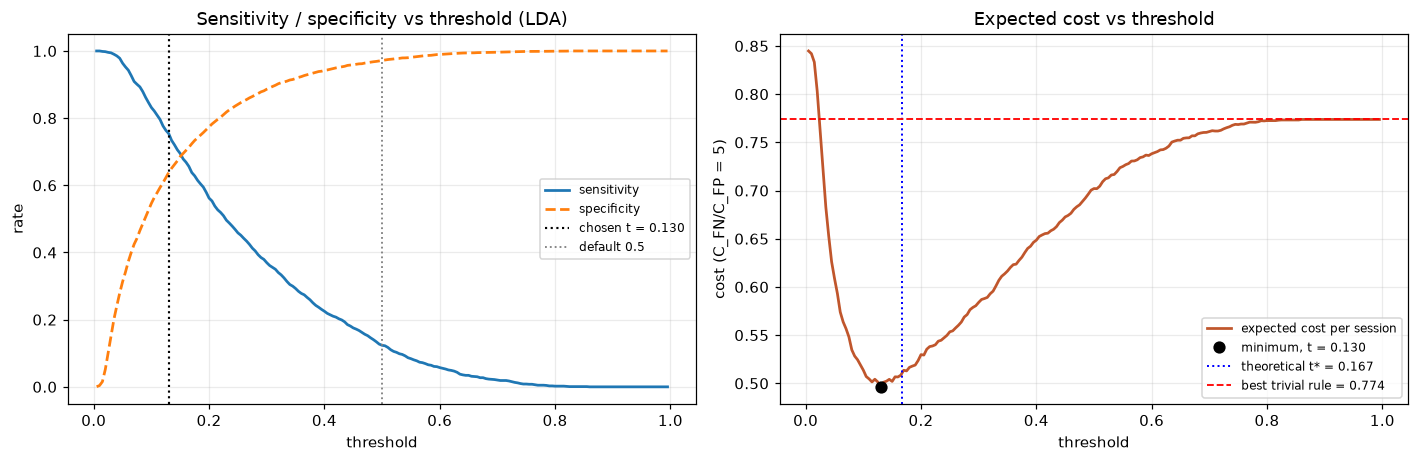

expected cost/session: at 0.5 0.7021 | at t* 0.5085 | at chosen t 0.4964
cost cut: 29.3% vs 0.5, 35.8% vs best trivial rule


,theoretical t*,empirical t,sensitivity,specificity
C_FN/C_FP,,,,
1,0.5000,0.620,0.0489,0.9922
2,0.3333,0.325,0.3333,0.9056
3,0.2500,0.255,0.4514,0.8462
5,0.1667,0.130,0.7540,0.6379
8,0.1111,0.080,0.8931,0.4652
10,0.0909,0.080,0.8931,0.4652


,threshold 0.5,threshold 0.130
buyers routed to support,19.1,116.7
support slots spent on non-buyers,24.0,306.0
buyers missed,135.6,38.1
non-buyers correctly left alone,821.2,539.2


In [34]:
P_FINAL = oof(pipe_of(FINAL_KEY))
ts, cost, sens, spec = cost_curve(ytr, P_FINAL)
T_EMP = float(ts[cost.argmin()]); prev = float(ytr.mean()); trivial = min(prev * COST, 1 - prev)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].plot(ts, sens, lw=1.8, label="sensitivity"); ax[0].plot(ts, spec, lw=1.8, ls="--", label="specificity")
ax[0].axvline(T_EMP, color="k", ls=":", lw=1.4, label=f"chosen t = {T_EMP:.3f}")
ax[0].axvline(.5, color="grey", ls=":", lw=1.2, label="default 0.5")
ax[0].set_xlabel("threshold"); ax[0].set_ylabel("rate"); ax[0].set_title(f"Sensitivity / specificity vs threshold ({FINAL})")
ax[0].legend(fontsize=8)
ax[1].plot(ts, cost, lw=1.8, color="#c0562c", label="expected cost per session")
ax[1].plot(T_EMP, cost.min(), "ko", ms=7, label=f"minimum, t = {T_EMP:.3f}")
ax[1].axvline(T_STAR, color="b", ls=":", lw=1.3, label=f"theoretical t* = {T_STAR:.3f}")
ax[1].axhline(trivial, color="r", ls="--", lw=1.2, label=f"best trivial rule = {trivial:.3f}")
ax[1].set_xlabel("threshold"); ax[1].set_ylabel(f"cost (C_FN/C_FP = {COST:g})"); ax[1].set_title("Expected cost vs threshold")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()
c_half = cost[np.abs(ts - .5).argmin()]
print(f"expected cost/session: at 0.5 {c_half:.4f} | at t* {cost[np.abs(ts - T_STAR).argmin()]:.4f} | at chosen t {cost.min():.4f}")
print(f"cost cut: {100 * (c_half - cost.min()) / c_half:.1f}% vs 0.5, {100 * (trivial - cost.min()) / trivial:.1f}% vs best trivial rule")
SWEEP = []
for r_ in [1, 2, 3, 5, 8, 10]:
    t2, c2, s2, sp2 = cost_curve(ytr, P_FINAL, ratio=r_); i = c2.argmin()
    SWEEP.append({"C_FN/C_FP": r_, "theoretical t*": 1 / (1 + r_), "empirical t": t2[i],
                  "sensitivity": s2[i], "specificity": sp2[i]})
display(pd.DataFrame(SWEEP).set_index("C_FN/C_FP"))
per = lambda r: {k: 1000 * v / len(ytr) for k, v in r.items() if k in ("TP", "FP", "FN", "TN")}
b5, bt = per(rates(ytr, P_FINAL, .5)), per(rates(ytr, P_FINAL, T_EMP))
display(pd.DataFrame({"threshold 0.5": b5, f"threshold {T_EMP:.3f}": bt},
                     index=["TP", "FP", "FN", "TN"]).rename(index={
    "TP": "buyers routed to support", "FP": "support slots spent on non-buyers",
    "FN": "buyers missed", "TN": "non-buyers correctly left alone"}).round(1))

**What it tells us.** Expected cost is minimised at **t = 0.130**, near the theoretical t* = 0.167. It sits a little lower because LDA's probabilities are not perfectly calibrated. At that threshold, cost is 29% below the cost at 0.5 and 36% below the best trivial rule. The sweep shows the operating point following the cost ratio: at ratio 2 the model is conservative (sensitivity 0.33, specificity 0.91); at ratio 8 it flags almost every plausible buyer (0.89 / 0.47). Ratios 8 and 10 give the same threshold because the cost curve is flat there.
**Real-world meaning.** Per 1,000 sessions, moving from 0.5 to 0.130 routes support to 117 buyers instead of 19 and cuts missed buyers from 136 to 38. The price is 306 support slots spent on non-buyers instead of 24, which means flagging about 42% of all sessions. Whether support staff can absorb that is a business decision, and it is exactly what the cost ratio encodes.

**Theory: the Bayes decision rule.** For a session with purchase probability p, flagging it costs (1 − p)·C_FP in
expectation, and not flagging it costs p·C_FN. Flag when p·C_FN > (1 − p)·C_FP, i.e. when
**p > C_FP / (C_FP + C_FN) = 1 / (1 + 5) = 0.167**. This is t\*, and it is optimal only if the probabilities are
calibrated. The empirical threshold (0.130) sits below it because LDA's probabilities are not perfectly
calibrated; Appendix A6 shows where. The same logic explains LDA's class **priors**: changing them adds a constant
to every session's log-odds, which is exactly equivalent to moving the threshold. Appendix A8 demonstrates this.

## §14 Held-out audit — one model, one look

**Purpose.** An honest estimate of performance on unseen data. The test set has not been touched. It is
opened now, once, for the single model chosen in §12 at the threshold fixed in §13. This is an audit, not
a chance to reconsider. **Method.** Confusion matrix; Wilson intervals for sensitivity and specificity;
a bootstrap interval for AUC (resampling this one set of predictions).

In [35]:
final_fit = pipe_of(FINAL_KEY).fit(Xtr, ytr)
p_test = final_fit.predict_proba(Xte)[:, 1]            # <-- the ONLY use of the test set
R = rates(yte, p_test, T_EMP); TEST_AUC = roc_auc_score(yte, p_test)
rng = np.random.default_rng(SEED)
boot = [roc_auc_score(yte.values[i], p_test[i]) for i in
        (rng.integers(0, len(yte), len(yte)) for _ in range(2000)) if yte.values[i].min() != yte.values[i].max()]
lo_a, hi_a = np.percentile(boot, [2.5, 97.5])
(lo, hi), (slo, shi) = wilson(R["TP"], R["TP"] + R["FN"]), wilson(R["TN"], R["TN"] + R["FP"])
print(f"FINAL MODEL {FINAL}  |  threshold {T_EMP:.3f} (fixed from training folds)\n")
display(pd.DataFrame([[R["TN"], R["FP"]], [R["FN"], R["TP"]]], index=["actual: no purchase", "actual: purchase"],
                     columns=["predicted: no", "predicted: yes"]))
print(f"\ntest AUC     {TEST_AUC:.4f}   95% bootstrap CI [{lo_a:.3f}, {hi_a:.3f}]")
print(f"sensitivity  {R['sens']:.4f}   95% Wilson CI   [{lo:.3f}, {hi:.3f}]")
print(f"specificity  {R['spec']:.4f}   95% Wilson CI   [{slo:.3f}, {shi:.3f}]")
cvr = rates(ytr, P_FINAL, T_EMP)
display(pd.DataFrame([
    {"estimate": "CV, non-nested (25-fold)", "AUC": SCORES[FINAL_KEY].mean(), "sensitivity": cvr["sens"], "specificity": cvr["spec"]},
    {"estimate": "CV, nested (5x5)", "AUC": NESTED, "sensitivity": np.nan, "specificity": np.nan},
    {"estimate": "held-out test (once)", "AUC": TEST_AUC, "sensitivity": R["sens"], "specificity": R["spec"]}]).set_index("estimate"))
print(f"CV (non-nested) minus test AUC: {SCORES[FINAL_KEY].mean() - TEST_AUC:+.4f} | nested minus test: {NESTED - TEST_AUC:+.4f}")

FINAL MODEL LDA  |  threshold 0.130 (fixed from training folds)



,predicted: no,predicted: yes
actual: no purchase,1646,960
actual: purchase,121,356



test AUC     0.7614   95% bootstrap CI [0.739, 0.783]
sensitivity  0.7463   95% Wilson CI   [0.705, 0.783]
specificity  0.6316   95% Wilson CI   [0.613, 0.650]


,AUC,sensitivity,specificity
estimate,,,
"CV, non-nested (25-fold)",0.7618,0.7540,0.6379
"CV, nested (5x5)",0.7602,NaN,NaN
held-out test (once),0.7614,0.7463,0.6316


CV (non-nested) minus test AUC: +0.0004 | nested minus test: -0.0011


**What it tells us.** On unseen data the model scores AUC **0.761** (95% CI 0.739–0.783), sensitivity **0.746** [0.705, 0.783] and specificity **0.632** [0.613, 0.650]. The CV estimate (0.7618) and the nested estimate (0.7602) are both within 0.002 of the test AUC and inside its interval. **The cross-validation estimates were honest.** The leakage-free pipeline and the parsimony rule did their job.
**Real-world meaning.** Deployed, the model would catch about three in four buyers while flagging a little over a third of non-buyers.

## §15 Refit on the full data

**Purpose.** With evaluation finished, refit the chosen specification on train + test, so the deployed
model uses every observation. Its performance estimate remains §14's held-out figure.

In [36]:
X_all = pd.concat([Xtr, Xte], ignore_index=True); y_all = pd.concat([ytr, yte], ignore_index=True)
PROD = pipe_of(FINAL_KEY).fit(X_all, y_all)
print(f"refitted {FINAL} [{FINAL_KEY[0]}:{FINAL_KEY[1]}] on all {len(X_all):,} sessions")

refitted LDA [C:poly2] on all 12,330 sessions


**What it tells us.** The deployed model is fitted on all 12,330 sessions. No new performance figure is reported here; the honest estimate remains §14's.

## §16 Interpretation

**Purpose.** What drives a purchase, in business terms. **Method.** Odds ratios from a main-effects
logistic model (numeric terms per one standard deviation of the transformed feature), plus partial
dependence plots from the final model, showing how predicted purchase probability moves with one
feature while the others stay as observed.

explanatory model: Logistic [B:zeroind], AUC 0.7618 (final predictive model 0.7618)


,coefficient,odds ratio
term,,
Month_Feb,-1.2030,0.3003
log1p(ExitRates),-1.1059,0.3309
Browser_3,-0.8656,0.4208
TrafficType_13,-0.7854,0.4560
SpecialDay_0.8,-0.7672,0.4643
log1p(ProductRelated_Duration),0.6403,1.8971
any(Administrative),0.5922,1.8079
Month_Nov,0.5481,1.7300
VisitorType_Returning_Visitor,-0.5358,0.5852


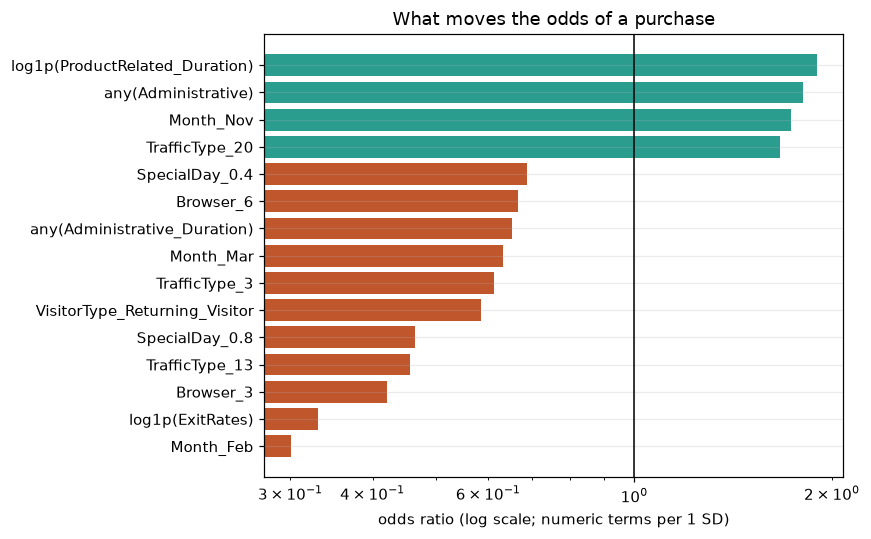

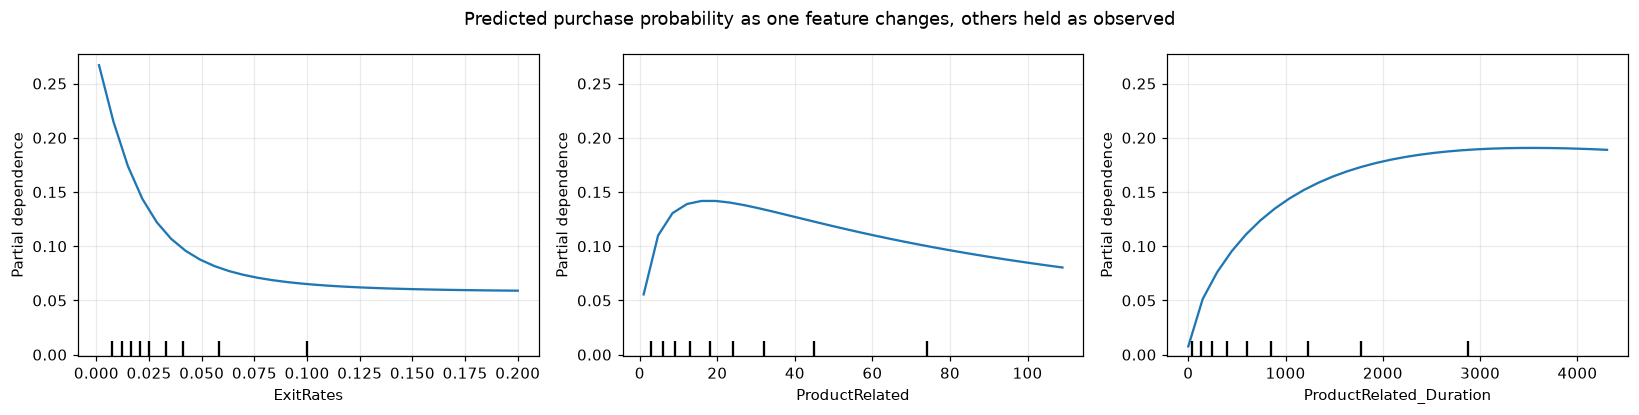

In [37]:
kI = BEST_D["Logistic"]                          # a main-effects logistic keeps coefficients readable
kI = kI if CONF[kI]["pre"].get("poly", 1) == 1 and not CONF[kI]["pre"].get("domain") else BEST_B["Logistic"]
expl = pipe_of(kI).fit(X_all, y_all)
names = expl.named_steps["ct"].get_feature_names_out(); coef = expl.named_steps["clf"].coef_[0]
OR = (pd.DataFrame({"term": [n.split("__", 1)[1] for n in names], "coefficient": coef, "odds ratio": np.exp(coef)})
        .assign(a=lambda d: d.coefficient.abs()).sort_values("a", ascending=False).drop(columns="a").head(15).set_index("term"))
print(f"explanatory model: Logistic [{kI[0]}:{kI[1]}], AUC {SCORES[kI].mean():.4f} "
      f"(final predictive model {SCORES[FINAL_KEY].mean():.4f})")
display(OR)
fig, ax = plt.subplots(figsize=(8, 5))
o = OR["odds ratio"].sort_values()
ax.barh(o.index, o.values, color=["#c0562c" if v < 1 else "#2a9d8f" for v in o.values])
ax.axvline(1, color="k", lw=1); ax.set_xscale("log"); ax.set_xlabel("odds ratio (log scale; numeric terms per 1 SD)")
ax.set_title("What moves the odds of a purchase"); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
X_pd = X_all.copy(); X_pd[NUMM] = X_pd[NUMM].astype(float)   # PDP needs float columns
PartialDependenceDisplay.from_estimator(PROD, X_pd, ["ExitRates", "ProductRelated", "ProductRelated_Duration"],
                                        ax=ax, grid_resolution=30, percentiles=(0.01, 0.95))
plt.suptitle("Predicted purchase probability as one feature changes, others held as observed"); plt.tight_layout(); plt.show()

**What it tells us — odds ratios.** The explanatory model is the carried-forward Logistic model. It has the same CV AUC as the final LDA (0.7618) and readable coefficients.
- **Strongest negatives:** February (OR 0.30), exit rate (0.33 per SD), holiday proximity 0.8 (0.46), returning visitors (0.59).
- **Strongest positives:** time on product pages (1.90 per SD), November (1.73), traffic source 20 (1.67).
- **Read `any(Administrative)` (1.81) and `any(Administrative_Duration)` (0.65) together, not separately.** They are nearly the same flag, since visiting an admin page almost always records a duration, so the model splits one effect into opposing coefficients. This is the collinearity §4.4 warned about. Combined, the effect is modestly positive (1.81 × 0.65 ≈ 1.18).
- Category odds ratios are relative to the other levels of that variable: every level is kept, and the ridge penalty centres them. Browser and traffic-source codes are anonymised, so they cannot be given a business meaning.

**What it tells us — partial dependence (final LDA model).**
- **Exit rate** is the steepest signal. Predicted purchase probability is about 0.27 when exit rates are near zero and falls to about 0.09 by an exit rate of 0.05, then flattens.
- **Time on product pages** raises probability from near 0 to about 0.19 by roughly 3,000 seconds, then plateaus.
- **Number of product pages** rises to a peak around 15–20 pages and then *falls*, because the plot holds time on product pages as observed. More pages in the same amount of time means less time per page, i.e. skimming. Depth of engagement predicts buying, not page count.

**Real-world meaning.** Visitors who stay on the pages they reach and spend real time on products are the ones worth routing to support. These are associations, not levers (§17): making visitors click through more pages would not make them buy.

## §17 Limitations

**Statistical**
- **Large-sample tests.** With ~9,000 rows every formal assumption test rejects. We relied on magnitudes and plots, because "significant" is not the same as "important".
- **Greedy, stage-wise search.** Each stage carries one configuration forward, so a combination that only pays off jointly could be missed.
- **Multiple comparisons.** About 45 comparisons at α = 0.05 means roughly 2 "significant" results are expected by chance. The parsimony rule, the nested CV (optimism +0.0015) and the held-out audit limit the damage; they do not remove it.
- **Density models on dummies.** Gaussian NB, LDA and QDA are applied to one-hot columns, which cannot be normal.
- **Session independence.** Returning visitors can appear in both training and validation folds, and there is no user ID to group by, so CV may be slightly optimistic. The held-out result suggests the effect is small.
- **One split.** The held-out estimate comes from one random split. Its confidence interval (±0.022 AUC) is the honest uncertainty.
- **SMOTENC** measured distances on unscaled numeric features, a likely reason it lost 0.066 AUC. A scaled variant was not tried.
- **The final choice is narrow.** LDA beat Logistic and QDA on cost by under 1%.
- **Duplicates.** Some sessions are exact copies (single-page bounces), and a few test sessions have an identical twin in training (§2.5). These are easy cases, so they flatter the held-out result slightly.

**Real-world**
- **Timing.** Durations and exit rates are only complete when a session ends. A mid-session prediction sees partial data, so live performance will be lower than reported.
- **`PageValues`** was excluded as leakage. A version computed only from earlier periods could add legitimate signal.
- **Scope.** One retailer, one year, one market: seasonality (the November peak) and drift are untested.
- **The cost ratio of 5 is assumed, not measured.** §13 shows the threshold moves with it.
- **Association, not cause.** Pushing visitors to view more product pages would not necessarily make them buy.
- **Capacity.** The chosen threshold flags about 42% of sessions, which may exceed what support staff can handle.
- **Feedback.** Once deployed, the support itself changes visitor behaviour and shifts future data.
- **Coverage.** January and April are absent, so the model has never seen them (§2.5).
- **Measurement.** Google Analytics cannot time the last page of a visit, so durations are biased downward and a recorded zero does not always mean no activity (§2.5).
- **Headroom.** Tree ensembles reach 0.786 AUC, so a better model exists outside the brief's methods.

## §18 Conclusion

In [38]:
LED = pd.DataFrame(LEDGER)
kA = A_KEYS["Logistic"]
print(f"final model        : {FINAL}  [{FINAL_KEY[0]}:{FINAL_KEY[1]}]  at threshold {T_EMP:.3f}")
print(f"AUC                : baseline {SCORES[kA].mean():.4f} -> final {SCORES[FINAL_KEY].mean():.4f} "
      f"(+{SCORES[FINAL_KEY].mean() - SCORES[kA].mean():.4f}) | nested {NESTED:.4f} | held-out {TEST_AUC:.4f}")
print(f"held-out           : sensitivity {R['sens']:.3f}, specificity {R['spec']:.3f}")
print(f"ceiling benchmark  : {bm[1]} {SCORES[bm].mean():.4f}")
print(f"leakage removed    : PageValues, worth {PREMIUM:.4f} AUC")
print(f"variants tried     : {len(LED)}  ->  " + ", ".join(f"{k}: {v}" for k, v in LED['verdict'].fillna('reference').value_counts().items()))

final model        : LDA  [C:poly2]  at threshold 0.130
AUC                : baseline 0.7517 -> final 0.7618 (+0.0101) | nested 0.7602 | held-out 0.7614
held-out           : sensitivity 0.746, specificity 0.632
ceiling benchmark  : RandomForest (500 trees) 0.7861
leakage removed    : PageValues, worth 0.1413 AUC
variants tried     : 49  ->  GAIN: 20, no sig. change: 20, reference: 4, LOSS: 4, FAILED TO FIT: 1


**Summary.**
- **Final model.** LDA on Yeo–Johnson-transformed features with degree-2 polynomial terms, operating at threshold 0.130. The threshold was chosen on training folds for C_FN/C_FP = 5.
- **Performance.** Best baseline AUC 0.752 → final 0.762 in CV → **0.761 on held-out data**, with sensitivity 0.746 and specificity 0.632. LDA itself improved from 0.741. CV and held-out agree within 0.001, so the evaluation was honest.
- **What moved the needle.** Removing leakage (0.141 of AUC that would not survive deployment); transformations (+0.006 to +0.013 AUC for every method); and the cost-based threshold (sensitivity 0.04 → 0.75 at the same AUC). Polynomial terms helped LDA only. Tuning mattered for QDA and NB. Rebalancing added nothing that threshold moving did not.
- **What did not.** Of 45 tested variants, 20 made no significant difference, 4 made things worse and 1 could not be fitted. All are in the ledger.
- **The limit.** Tree ensembles reach 0.786, so about 0.025 AUC of nonlinear signal lies beyond the brief's methods. That is the clearest next step if the extra accuracy is worth losing interpretability.
- **Post-hoc checks (Appendix, CV only).** KNN (0.751) and splines (+0.004, not significant) do not beat the final model, which confirms the choice. About 27% of flagged sessions buy, 1.8× the base rate. The threshold is stable (95% interval 0.110–0.153, cost within 1.7%). More data of the same kind would help only a little, and changing LDA's priors is exactly a threshold shift.

## Appendix — post-hoc analyses (CV only)

These analyses were added **after** the held-out audit in §14. Workflow rule 4 forbids choosing a model after seeing
test results, so **nothing here can change the final model**. Every result below comes from training-data
cross-validation. The one exception is A3, which reuses §14's single set of test predictions without refitting anything.

### A1. K-nearest neighbours
**Purpose.** KNN is the standard non-parametric classifier: it assumes no distribution and no boundary shape.
**Method.** The same features as the best logistic model; k chosen by 5-fold CV, then scored on the shared 25 folds.
Small k is flexible and high-variance; large k is smooth and high-bias.

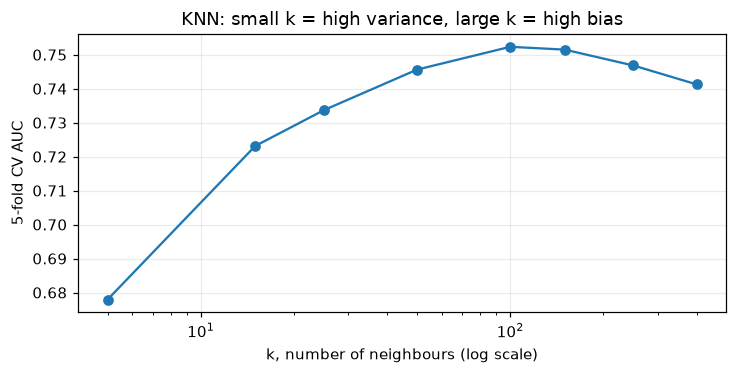

best k = 100: 25-fold AUC 0.7507 vs final LDA 0.7618 (Δ -0.0111, corrected p = 0.0408)


In [39]:
from sklearn.neighbors import KNeighborsClassifier
kL = BEST_D["Logistic"]; preK = CONF[kL]["pre"]
KS = [5, 15, 25, 50, 100, 150, 250, 400]
knn_cv = [cv5(build(KNeighborsClassifier(n_neighbors=k), **preK)).mean() for k in KS]
K_BEST = KS[int(np.nanargmax(knn_cv))]
fig, ax = plt.subplots(figsize=(6.8, 3.5)); ax.plot(KS, knn_cv, "o-"); ax.set_xscale("log")
ax.set_xlabel("k, number of neighbours (log scale)"); ax.set_ylabel("5-fold CV AUC")
ax.set_title("KNN: small k = high variance, large k = high bias"); plt.tight_layout(); plt.show()
record("P", f"KNN, k = {K_BEST}", "KNN", KNeighborsClassifier(n_neighbors=K_BEST), preK, ref=FINAL_KEY,
       note="post-hoc; not eligible as final model")
kK = ("P", f"KNN, k = {K_BEST}", "KNN")
d_, p_ = corrected_ttest(SCORES[kK], SCORES[FINAL_KEY])
print(f"best k = {K_BEST}: 25-fold AUC {SCORES[kK].mean():.4f} vs final {FINAL} {SCORES[FINAL_KEY].mean():.4f} "
      f"(Δ {d_:+.4f}, corrected p = {p_:.3g})")

**What it tells us.** The curve has the textbook shape: CV AUC rises from 0.678 at k = 5 (flexible, high variance), peaks at k = 100, and falls to 0.741 at k = 400 (over-smoothed, high bias). The best KNN reaches 0.751, significantly *below* the final LDA (−0.011, p = 0.04). With about 70 dimensions after one-hot encoding, distances carry less information (the curse of dimensionality), so a method that assumes no structure does worse than a structured linear one. This supports the choice of model families the brief prescribes.

### A2. Splines and step functions
**Purpose.** Polynomials (§7) impose one global curve. Splines fit piecewise cubics joined smoothly at knots, and
step functions fit a constant within each bin. Both are the standard ways to go beyond linearity locally.
**Method.** Replace the numeric transform in logistic regression with each basis, fitted inside every fold, and
compare with the carried-forward logistic model. Splines are fitted on log(1+x) with uniform knots, because
quantile knots collapse for features that are mostly zero.

In [40]:
from sklearn.preprocessing import SplineTransformer, KBinsDiscretizer
def record_pipe(stage, variant, model, p, ref, note=""):
    key = (stage, variant, model); s = rcv(p); SCORES[key] = s
    d, pv = corrected_ttest(s, SCORES[ref])
    LEDGER.append({"stage": stage, "variant": variant, "model": model, "CV AUC": s.mean(), "SD": s.std(ddof=1),
                   "vs": f"{ref[0]}:{ref[1]}", "Δ AUC": d, "p": pv,
                   "verdict": ("GAIN" if d > 0 else "LOSS") if pv < 0.05 else "no sig. change", "note": note})
    return key
def basis_pipe(num_tf, clf):
    num_p = Pipeline([("imp", SimpleImputer(strategy="median")), ("tf", num_tf), ("sc", StandardScaler())])
    return Pipeline([("ct", ColumnTransformer([("num", num_p, NUMM), ("cat", cat_pipe(), CAT)])), ("clf", clf)])
spline = lambda n: Pipeline([("log", FunctionTransformer(np.log1p)),
                             ("spl", SplineTransformer(n_knots=n, degree=3, knots="uniform", extrapolation="linear"))])
BASES = {"cubic spline, 4 knots": spline(4), "cubic spline, 6 knots": spline(6), "cubic spline, 10 knots": spline(10),
         "step functions, 4 bins": KBinsDiscretizer(n_bins=4, encode="onehot-dense", strategy="quantile"),
         "step functions, 8 bins": KBinsDiscretizer(n_bins=8, encode="onehot-dense", strategy="quantile")}
kL = BEST_D["Logistic"]; rows_ = []
for v, tf in BASES.items():
    record_pipe("P", v, "Logistic", basis_pipe(tf, LogisticRegression(max_iter=5000)), ref=kL, note="post-hoc")
    rows_.append(LEDGER[-1])
display(pd.DataFrame(rows_).set_index("variant")[["CV AUC", "SD", "Δ AUC", "p", "verdict"]])
pk = ("C", "poly2", "Logistic")
print(f"reference: Logistic [{kL[0]}:{kL[1]}] {SCORES[kL].mean():.4f}"
      + (f" | polynomial degree 2 on the same model: {SCORES[pk].mean():.4f}" if pk in SCORES else ""))

,CV AUC,SD,Δ AUC,p,verdict
variant,,,,,
"cubic spline, 4 knots",0.7645,0.0163,0.0028,0.1807,no sig. change
"cubic spline, 6 knots",0.7655,0.0152,0.0037,0.1415,no sig. change
"cubic spline, 10 knots",0.7628,0.0152,0.0010,0.7464,no sig. change
"step functions, 4 bins",0.7579,0.0161,-0.0039,0.0117,LOSS
"step functions, 8 bins",0.7616,0.0150,-0.0001,0.9497,no sig. change


reference: Logistic [B:zeroind] 0.7618 | polynomial degree 2 on the same model: 0.7649


**What it tells us.** No basis significantly beats the carried-forward logistic model. The best spline (6 knots) gains +0.004 (p = 0.14), about what polynomial degree 2 gained (+0.003, §7). Coarse step functions *lose* (4 bins: −0.004, p = 0.01), because four constant pieces discard within-bin detail; 8 bins recover it (−0.0001). Three routes to local nonlinearity (polynomials, splines and steps) agree there is little left to gain in a model that treats features additively. The ceiling gap (§10) therefore points to structure beyond additive, low-order terms, such as threshold effects and interactions involving the categorical variables, which tree ensembles capture automatically.

### A3. Precision, NPV and F1
**Purpose.** Sensitivity and specificity describe the model from the customer's side. Precision (PPV) describes it
from the support team's side: of the sessions we flag, how many buy? With a 15.5% base rate this can be low even
when sensitivity is high. **Method.** The final model's out-of-fold predictions, plus §14's held-out confusion
matrix reused as-is; lift is precision divided by the base rate.

,sensitivity (recall),specificity,precision (PPV),NPV,F1,lift = PPV / base rate
estimate,,,,,,
"CV, t = 0.5",0.1237,0.9716,0.4436,0.8583,0.1934,2.8666
"CV, t = 0.130",0.7540,0.6379,0.2760,0.9341,0.4041,1.7837
"held-out (§14), t = 0.130",0.7463,0.6316,0.2705,0.9315,0.3971,1.7481


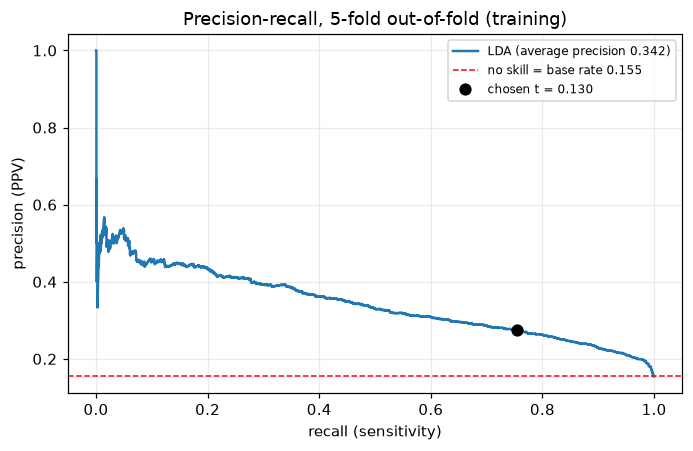

In [41]:
from sklearn.metrics import precision_recall_curve, average_precision_score
def ppv_npv_f1(r):
    ppv = r["TP"] / (r["TP"] + r["FP"]) if r["TP"] + r["FP"] else np.nan
    npv = r["TN"] / (r["TN"] + r["FN"]) if r["TN"] + r["FN"] else np.nan
    return ppv, npv, 2 * ppv * r["sens"] / (ppv + r["sens"])
rows_ = []
for lab, r_ in [("CV, t = 0.5", rates(ytr, P_FINAL, .5)), (f"CV, t = {T_EMP:.3f}", rates(ytr, P_FINAL, T_EMP)),
                (f"held-out (§14), t = {T_EMP:.3f}", R)]:
    ppv, npv, f1 = ppv_npv_f1(r_)
    rows_.append({"estimate": lab, "sensitivity (recall)": r_["sens"], "specificity": r_["spec"],
                  "precision (PPV)": ppv, "NPV": npv, "F1": f1, "lift = PPV / base rate": ppv / ytr.mean()})
display(pd.DataFrame(rows_).set_index("estimate"))
pr_, rc_, _ = precision_recall_curve(ytr, P_FINAL); AP = average_precision_score(ytr, P_FINAL)
r_ = rates(ytr, P_FINAL, T_EMP)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(rc_, pr_, lw=1.6, label=f"{FINAL} (average precision {AP:.3f})")
ax.axhline(ytr.mean(), color="r", ls="--", lw=1, label=f"no skill = base rate {ytr.mean():.3f}")
ax.plot(r_["sens"], ppv_npv_f1(r_)[0], "ko", ms=7, label=f"chosen t = {T_EMP:.3f}")
ax.set_xlabel("recall (sensitivity)"); ax.set_ylabel("precision (PPV)")
ax.set_title("Precision-recall, 5-fold out-of-fold (training)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**What it tells us.** At the chosen threshold **about 27% of flagged sessions buy** (CV 0.276, held-out 0.271): 1.8 times the 15.5% base rate. At 0.5, precision is higher (0.44), but only 12% of buyers are caught. NPV is 0.93: a session the model passes over has only about a 7% chance of being a buyer. CV and held-out figures agree closely again.

**Real-world meaning.** Roughly 3 in 4 support conversations go to a non-buyer. That is the price of catching three-quarters of buyers, and it is worth paying only because a missed buyer costs five wasted slots. If support is scarce, the precision–recall curve shows the trade: raising the threshold lifts precision but lowers recall.

### A4. How stable is the chosen threshold?
**Purpose.** t = 0.130 was picked from one set of out-of-fold predictions. Would a slightly different sample pick
something very different? **Method.** Bootstrap: resample the training sessions 500 times, find the cost-optimal
threshold in each resample, and check how much the cost changes across the resulting interval.

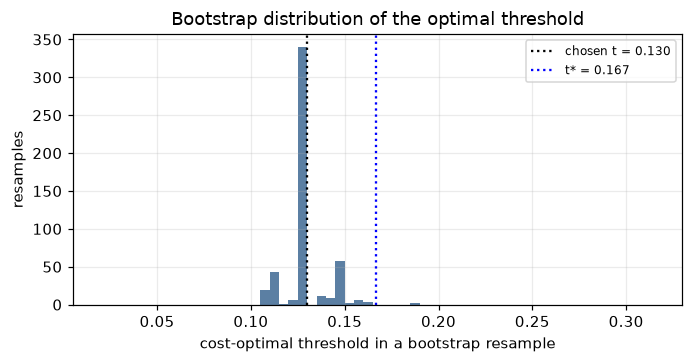

95% bootstrap interval for the optimal threshold: [0.110, 0.153]
expected cost across that interval: 0.4964 to 0.5046 (worst case 1.7% above the minimum)


In [42]:
rng = np.random.default_rng(SEED); TB = []
for _ in range(500):
    i = rng.integers(0, len(ytr), len(ytr))
    ts_, c_, _, _ = cost_curve(ytr.values[i], P_FINAL[i]); TB.append(ts_[c_.argmin()])
TB = np.array(TB); lo_t, hi_t = np.percentile(TB, [2.5, 97.5])
ts_, c_, _, _ = cost_curve(ytr, P_FINAL); band = c_[(ts_ >= lo_t - 1e-9) & (ts_ <= hi_t + 1e-9)]
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.hist(TB, bins=np.arange(0.02, 0.32, 0.005), color="#5b7fa3")
ax.axvline(T_EMP, color="k", ls=":", label=f"chosen t = {T_EMP:.3f}"); ax.axvline(T_STAR, color="b", ls=":", label=f"t* = {T_STAR:.3f}")
ax.set_xlabel("cost-optimal threshold in a bootstrap resample"); ax.set_ylabel("resamples")
ax.set_title("Bootstrap distribution of the optimal threshold"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"95% bootstrap interval for the optimal threshold: [{lo_t:.3f}, {hi_t:.3f}]")
print(f"expected cost across that interval: {band.min():.4f} to {band.max():.4f} "
      f"(worst case {100 * (band.max() - c_.min()) / c_.min():.1f}% above the minimum)")

**What it tells us.** Most resamples choose 0.130 exactly, and 95% fall within [0.110, 0.153]. Anywhere in that range the expected cost is at most 1.7% above the minimum. The cost curve is flat near its minimum, so the exact choice of 0.130 matters little and the operating point is robust. t* = 0.167 falls outside the interval, which matches the calibration offset shown in A6.

### A5. Learning curve: would more data help?
**Purpose.** Directly test whether performance is limited by the *amount* of data. **Method.** Refit the final
model on growing fractions of each training fold and score both the data it was trained on and the validation fold.
A large, persistent gap means variance, so more data would help; converging curves mean bias, so more of the same
data would not.

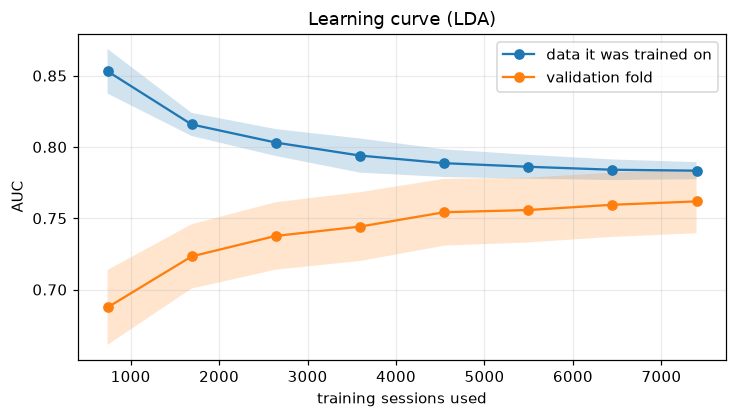

validation AUC 0.6875 at n = 739  ->  0.7618 at n = 7,397; last step added +0.0024
gap between training and validation AUC: 0.1656 at the smallest size, 0.0215 at full size


In [43]:
from sklearn.model_selection import learning_curve
SIZES, TR_S, VA_S = learning_curve(pipe_of(FINAL_KEY), Xtr, ytr, train_sizes=np.linspace(0.1, 1.0, 8), cv=skf,
                                   scoring="roc_auc", n_jobs=-1, shuffle=True, random_state=SEED)
fig, ax = plt.subplots(figsize=(6.8, 3.9))
for s_, lab in [(TR_S, "data it was trained on"), (VA_S, "validation fold")]:
    ax.plot(SIZES, s_.mean(1), "o-", label=lab)
    ax.fill_between(SIZES, s_.mean(1) - s_.std(1), s_.mean(1) + s_.std(1), alpha=.2)
ax.set_xlabel("training sessions used"); ax.set_ylabel("AUC"); ax.set_title(f"Learning curve ({FINAL})"); ax.legend()
plt.tight_layout(); plt.show()
v_ = VA_S.mean(1); t_ = TR_S.mean(1)
print(f"validation AUC {v_[0]:.4f} at n = {SIZES[0]:,}  ->  {v_[-1]:.4f} at n = {SIZES[-1]:,}; "
      f"last step added {v_[-1] - v_[-2]:+.4f}")
print(f"gap between training and validation AUC: {t_[0] - v_[0]:.4f} at the smallest size, {t_[-1] - v_[-1]:.4f} at full size")

**What it tells us.** Validation AUC climbs steeply at first (0.688 on 739 sessions), then flattens: the last step adds only +0.002. The gap between training and validation AUC closes from 0.166 to 0.022. The model is now mostly bias-limited. More sessions of the *same* kind would help only a little; new information (richer features, §10's flexible models) would help more.

**Real-world meaning.** Collecting more months of the same logs is not the main lever. Recording richer signals, such as timing of the last page or cart events, would be.

### A6. Calibration of the final model
**Purpose.** The Bayes threshold t\* = 0.167 is optimal only if predicted probabilities are calibrated. This checks
whether LDA's are, and so explains why the empirical threshold came out lower.

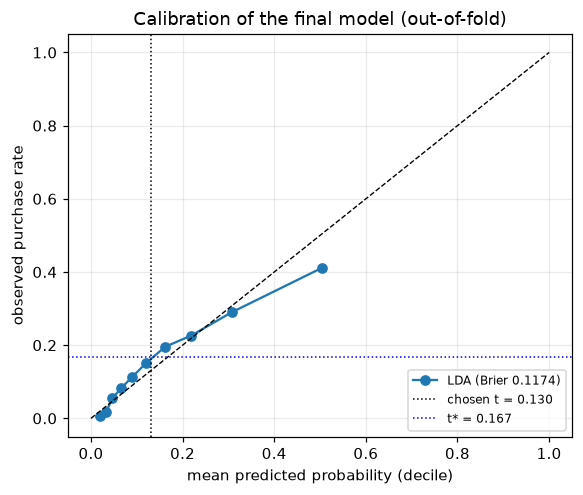

sessions scored within ±0.02 of t = 0.130: 1,002; their observed purchase rate 0.163 (t* = 0.167)
mean predicted probability 0.1567 vs observed purchase rate 0.1548


In [44]:
fp_, mp_ = calibration_curve(ytr, P_FINAL, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.4, 4.6))
ax.plot(mp_, fp_, "o-", label=f"{FINAL} (Brier {brier_score_loss(ytr, P_FINAL):.4f})"); ax.plot([0, 1], [0, 1], "k--", lw=.9)
ax.axvline(T_EMP, color="k", ls=":", lw=1, label=f"chosen t = {T_EMP:.3f}")
ax.axhline(T_STAR, color="b", ls=":", lw=1, label=f"t* = {T_STAR:.3f}")
ax.set_xlabel("mean predicted probability (decile)"); ax.set_ylabel("observed purchase rate")
ax.set_title("Calibration of the final model (out-of-fold)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
near = np.abs(P_FINAL - T_EMP) < 0.02
print(f"sessions scored within ±0.02 of t = {T_EMP:.3f}: {int(near.sum()):,}; their observed purchase rate "
      f"{ytr[near].mean():.3f} (t* = {T_STAR:.3f})")
print(f"mean predicted probability {P_FINAL.mean():.4f} vs observed purchase rate {ytr.mean():.4f}")

**What it tells us.** On average the model is calibrated: it predicts 0.157 against an observed 0.155. Locally it is not. Between about 0.1 and 0.2 it under-predicts: sessions scored 0.13 ± 0.02 actually buy at 0.163, almost exactly t* = 0.167. At the top it over-predicts (predicted 0.50, observed 0.41). This is why the empirical threshold (0.130) sits below the theoretical one. Both mark roughly the same sessions, 0.130 on the model's scale and 0.167 on the true-probability scale, so threshold choice must use the model's own out-of-fold predictions, as §13 did.

### A7. Counting parameters: why QDA struggles
**Purpose.** Make the variance argument of §7 concrete. **Method.** LDA estimates 2 class means plus **one**
covariance matrix of d(d+1)/2 values; QDA estimates **one per class**.

In [45]:
def dims(key): return pipe_of(key)[:-1].fit(Xtr, ytr).transform(Xtr.iloc[:5]).shape[1]
dL, dQ = dims(FINAL_KEY), dims(BEST_D["QDA"])
cov = lambda d: d * (d + 1) // 2
display(pd.DataFrame([
    {"model": f"LDA, final feature set (d = {dL})", "mean parameters": 2 * dL, "covariance parameters": cov(dL), "total": 2 * dL + cov(dL)},
    {"model": f"LDA, QDA's feature set (d = {dQ})", "mean parameters": 2 * dQ, "covariance parameters": cov(dQ), "total": 2 * dQ + cov(dQ)},
    {"model": f"QDA (d = {dQ})", "mean parameters": 2 * dQ, "covariance parameters": 2 * cov(dQ), "total": 2 * dQ + 2 * cov(dQ)}]).set_index("model"))
print(f"QDA estimates {cov(dQ):,} covariance values for buyers alone from {int(ytr.sum()):,} buyer sessions "
      f"({cov(dQ) / ytr.sum():.1f} per buyer).")

,mean parameters,covariance parameters,total
model,,,
"LDA, final feature set (d = 101)",202,5151,5353
"LDA, QDA's feature set (d = 76)",152,2926,3078
QDA (d = 76),152,5852,6004


QDA estimates 2,926 covariance values for buyers alone from 1,431 buyer sessions (2.0 per buyer).


**What it tells us.** On QDA's feature set (76 columns), LDA estimates 3,078 parameters and QDA 6,004. The 2,926 covariance values QDA needs for buyers alone rest on just 1,431 buyer sessions, about 2 per buyer. That is why unregularised QDA could not be fitted (§5), and why reg_param = 0.1, which shrinks each class's covariance toward a simpler form, helped so much (§8.3). The final LDA has more parameters in total (5,353, over 101 columns), but its single shared covariance is estimated from all 9,247 sessions.

### A8. LDA priors are a threshold in disguise
**Purpose.** Evidence for the claim in §13. **Method.** Refit the final LDA with equal priors (0.5 / 0.5) instead of
the data's 15.5%, then compare its ranking and its decisions with the original model.

In [46]:
P_EQ = oof(pipe_of(FINAL_KEY).set_params(clf__priors=[0.5, 0.5]))
agree = ((P_EQ >= 0.5) == (P_FINAL >= ytr.mean())).mean()
display(pd.DataFrame([
    {"LDA priors": f"from the data ({ytr.mean():.3f} buyers)", "CV AUC": roc_auc_score(ytr, P_FINAL),
     "sensitivity @ 0.5": rates(ytr, P_FINAL, .5)["sens"], "specificity @ 0.5": rates(ytr, P_FINAL, .5)["spec"]},
    {"LDA priors": "equal (0.5 / 0.5)", "CV AUC": roc_auc_score(ytr, P_EQ),
     "sensitivity @ 0.5": rates(ytr, P_EQ, .5)["sens"], "specificity @ 0.5": rates(ytr, P_EQ, .5)["spec"]}]).set_index("LDA priors"))
print(f"equal-prior LDA at threshold 0.5 vs data-prior LDA at threshold {ytr.mean():.3f} (the base rate): "
      f"identical decisions for {agree:.2%} of sessions")

,CV AUC,sensitivity @ 0.5,specificity @ 0.5
LDA priors,,,
from the data (0.155 buyers),0.7616,0.1237,0.9716
equal (0.5 / 0.5),0.7616,0.6785,0.6940


equal-prior LDA at threshold 0.5 vs data-prior LDA at threshold 0.155 (the base rate): identical decisions for 99.98% of sessions


**What it tells us.** Changing the priors from the data's 15.5% to 50/50 leaves AUC unchanged (0.7616), because the ranking of sessions is identical. Only the operating point at 0.5 moves: sensitivity 0.12 → 0.68, specificity 0.97 → 0.69. Equal-prior LDA at 0.5 makes **the same decision as data-prior LDA at threshold 0.155 (the base rate) for 99.98% of sessions**. The rest come from class proportions varying slightly between folds. Priors are a threshold in disguise, exactly as the Bayes rule in §13 predicts.

### A9. Does the CV scheme matter?
**Purpose.** Evidence for the choice of repeated 5-fold CV. **Method.** Score the final model under three schemes.

In [47]:
rows_ = []
for n_, cv_ in {"5-fold, one pass": StratifiedKFold(5, shuffle=True, random_state=SEED),
                "10-fold, one pass": StratifiedKFold(10, shuffle=True, random_state=SEED),
                "5-fold x 5 repeats (used)": rskf}.items():
    t0_ = time.time(); s_ = cross_val_score(pipe_of(FINAL_KEY), Xtr, ytr, cv=cv_, scoring="roc_auc", n_jobs=-1)
    rows_.append({"scheme": n_, "folds": len(s_), "mean AUC": s_.mean(), "SD across folds": s_.std(ddof=1),
                  "seconds": time.time() - t0_})
display(pd.DataFrame(rows_).set_index("scheme"))
print("LOOCV is not usable with AUC: a one-session fold contains only one class, so AUC is undefined.")

,folds,mean AUC,SD across folds,seconds
scheme,,,,
"5-fold, one pass",5,0.7618,0.0250,0.5037
"10-fold, one pass",10,0.7616,0.0304,1.3052
5-fold x 5 repeats (used),25,0.7618,0.0170,2.8583


LOOCV is not usable with AUC: a one-session fold contains only one class, so AUC is undefined.


**What it tells us.** All three schemes estimate the same AUC (0.7616–0.7618), so no conclusion depends on the choice. 10-fold shows more fold-to-fold spread (SD 0.030) because each validation fold is half the size. Repeating 5-fold five times averages over five different random splittings, which is what makes the fold-by-fold comparisons between variants (§5–§10) stable. It costs about 4× one pass: 1.4 s here, still modest across ~50 variants.

*Runtime of the full notebook:*

In [48]:
print(f"total runtime {time.time() - T0:.0f}s")

total runtime 236s
